# RSNA-MICCAI MGMT Radiogenomic Classification
## Tumor-Focused Multi-View ViT + BiomedCLIP VLM Adapter + Quantitative ROI Features
### Leakage-controlled evaluation + final training on ALL usable labeled patients

**Dataset:** RSNA-MICCAI Brain Tumor Radiogenomic Classification  
**Target:** MGMT promoter methylation  
**Modalities:** FLAIR, T1w, T1wCE, T2w

This notebook is the performance-focused revision of the previous model.

## What is fixed

### Imaging / preprocessing
- Physical DICOM geometry is read with **SimpleITK/GDCM**.
- Every modality is reoriented to LPS.
- All modalities are resampled into a **shared isotropic patient grid**.
- Robust brain-restricted intensity normalization is applied.
- The previous entropy-only slice selection is replaced by **multimodal tumor-likeness localization** using FLAIR/T2/T1CE intensity abnormalities plus left-right asymmetry.
- Three anatomically matched tumor-focused slices are selected and the **same crop coordinates** are applied to every MRI modality.
- Whole-brain montage distortion is eliminated.

### Model
- Multi-view DINO ViT with learned view attention.
- **Modality dropout** during ViT training to reduce dependence on weak/noisy sequences.
- Frozen BiomedCLIP per-view embeddings + a trainable **attention adapter** rather than only PCA/logistic regression.
- Nested modality-subset selection for the VLM branch.
- A quantitative pseudo-ROI feature branch (first order + GLCM + shape-like features).
- Leakage-aware ViT + VLM + quantitative-feature stacking.

### Evaluation
- 5-fold patient-level OOF evaluation: every usable labeled patient receives one prediction from a model that did not train on that patient.
- Larger inner validation split for more stable early stopping.
- ROC-AUC remains the primary metric.
- Accuracy/F1/sensitivity/specificity are also reported using **fold-specific thresholds selected only from training/inner-validation data**.
- The organizer-flagged IDs remain in the primary full-cohort experiment, but are excluded from representative XAI cases and are reported separately in a sensitivity table.

### Final all-data training
After OOF evaluation, the notebook trains:
- final ViT on **all usable labeled patients**,
- final VLM adapter on **all usable labeled patients**,
- final quantitative-feature model on **all usable labeled patients**.

This preserves an honest evaluation while satisfying the requirement that the final deployable models use the complete labeled cohort.

> Important: tumor localization below is an automated **pseudo-ROI**, not an expert BraTS segmentation. It improves tumor focus without pretending that an expert mask is available in the Kaggle radiogenomic data.

## 1. Kaggle GPU / dependency setup

In [1]:
# ================================================================
# P100 / T4 SAFE SETUP
# Run this cell before the first `import torch`.
# ================================================================
import os
import sys
import subprocess

# Reduce CUDA fragmentation on 16GB Kaggle GPUs.
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

def shell(cmd):
    print("+", cmd)
    subprocess.check_call(cmd, shell=True)

def gpu_names_without_torch():
    try:
        txt = subprocess.check_output(
            ["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"],
            text=True,
            stderr=subprocess.STDOUT
        )
        return [x.strip() for x in txt.splitlines() if x.strip()]
    except Exception as e:
        print("GPU detection failed:", repr(e))
        return []

gpu_names = gpu_names_without_torch()
print("Detected GPU(s):", gpu_names or "none")
is_p100 = any("P100" in x.upper() for x in gpu_names)

if is_p100:
    print("Tesla P100 detected. Installing Pascal-compatible PyTorch/cu124.")
    shell(f"{sys.executable} -m pip uninstall -y torch torchvision torchaudio")
    shell(
        f"{sys.executable} -m pip install --no-cache-dir "
        "torch==2.5.1 torchvision==0.20.1 torchaudio==2.5.1 "
        "--index-url https://download.pytorch.org/whl/cu124"
    )

shell(
    f"{sys.executable} -m pip install -q "
    "pydicom SimpleITK timm open_clip_torch transformers huggingface_hub "
    "scikit-image"
)

print("Dependency setup complete.")

Detected GPU(s): ['NVIDIA GeForce RTX 5090']
+ c:\Users\zisan\anaconda3\envs\cuda_test\python.exe -m pip install -q pydicom SimpleITK timm open_clip_torch transformers huggingface_hub scikit-image
Dependency setup complete.


## 2. Imports, GPU smoke test and reproducibility

In [2]:
import os
import gc
import json
import math
import random
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageEnhance

import SimpleITK as sitk
from scipy import ndimage as ndi
from scipy.stats import skew, kurtosis

from skimage.feature import graycomatrix, graycoprops
from skimage.measure import regionprops, perimeter

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import timm
import open_clip

from sklearn.model_selection import (
    StratifiedKFold, train_test_split, GridSearchCV, cross_val_predict
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, roc_curve, average_precision_score,
    precision_recall_curve, accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, brier_score_loss
)
from sklearn.calibration import calibration_curve

import joblib
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = True
        torch.backends.cudnn.deterministic = False

seed_everything()

print("PyTorch:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Capability:", torch.cuda.get_device_capability(0))
    print("Compiled architectures:", torch.cuda.get_arch_list())

    # Real CUDA test.
    a = torch.randn(32, 32, device="cuda")
    b = torch.randn(32, 32, device="cuda")
    c = a @ b
    torch.cuda.synchronize()
    del a, b, c
    DEVICE = torch.device("cuda")
    print("CUDA smoke test: PASSED")
else:
    DEVICE = torch.device("cpu")
    print("WARNING: full model training on CPU will be slow.")

print("DEVICE:", DEVICE)

PyTorch: 2.9.0.dev20250825+cu128
CUDA build: 12.8
CUDA available: True
GPU: NVIDIA GeForce RTX 5090
Capability: (12, 0)
Compiled architectures: ['sm_61', 'sm_70', 'sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120']
CUDA smoke test: PASSED
DEVICE: cuda


## 3. Configuration

In [3]:
# ----------------------------
# Cohort / evaluation
# ----------------------------
N_FOLDS = 5
INNER_VAL_FRAC = 0.20
DEFAULT_THRESHOLD = 0.50
FLAGGED_IDS = {"00109", "00123", "00709"}

# Use all available labeled patients.
MAX_PATIENTS = None
DEBUG = False
DEBUG_N = 60

# ----------------------------
# Preprocessing
# ----------------------------
MODALITIES = ["FLAIR", "T1w", "T1wCE", "T2w"]
N_MODALITIES = 4
SLICES_PER_MODALITY = 3
N_VIEWS = 12

REFERENCE_MODALITY_ORDER = ["T1wCE", "FLAIR", "T2w", "T1w"]
TARGET_SPACING_MM = (1.5, 1.5, 1.5)
MAX_ISO_DIM = 256

IMAGE_SIZE = 224
PSEUDO_MASK_PERCENTILE = 96.5
MIN_COMPONENT_VOXELS = 50
TUMOR_CROP_MARGIN = 0.35
MIN_CROP_PIXELS = 80

# N4 can be very slow on 585×4 MRI volumes.
# Robust brain-restricted normalization is ON by default.
USE_N4 = False

# ----------------------------
# DataLoader
# ----------------------------
# 0 intentionally avoids Kaggle/Jupyter multiprocessing cleanup warnings.
NUM_WORKERS = 0

# ----------------------------
# ViT
# ----------------------------
VIT_MODEL_NAME = "vit_small_patch16_224.dino"
VIT_BATCH_SIZE = 1
VIT_GRAD_ACCUM_STEPS = 3  # effective batch ≈ 3 with much lower peak GPU memory
# Safer for the final all-patient fit after the long CV/XAI run on 16GB GPUs.
FINAL_VIT_BATCH_SIZE = 1
VIT_HEAD_EPOCHS = 1
VIT_FINETUNE_EPOCHS = 6
VIT_HEAD_LR = 8e-4
VIT_BACKBONE_LR = 2e-5
VIT_FINETUNE_HEAD_LR = 2e-4
VIT_UNFREEZE_BLOCKS = 4
VIT_PATIENCE = 2
VIT_DROPOUT = 0.30
MODALITY_DROPOUT_P = 0.15
USE_TTA = True

# ----------------------------
# VLM
# ----------------------------
BIOMEDCLIP_NAME = "hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224"
VLM_BATCH_SIZE = 4
VLM_ADAPTER_EPOCHS = 14
VLM_ADAPTER_LR = 3e-4
VLM_ADAPTER_PATIENCE = 3
VLM_HIDDEN = 192

# Nested modality-selection candidates for VLM.
MODALITY_SUBSETS = {
    "FLAIR": ["FLAIR"],
    "T2": ["T2w"],
    "T1CE": ["T1wCE"],
    "FLAIR+T2": ["FLAIR", "T2w"],
    "FLAIR+T1+T2": ["FLAIR", "T1w", "T2w"],
    "FLAIR+T1CE": ["FLAIR", "T1wCE"],
    "ALL4": ["FLAIR", "T1w", "T1wCE", "T2w"],
}

# ----------------------------
# Explainability
# ----------------------------
N_GLOBAL_GRADCAM = 100

# ----------------------------
# Final all-data models
# ----------------------------
TRAIN_FINAL_ALL_DATA_MODELS = True
RUN_COMPETITION_TEST_INFERENCE = False

# ----------------------------
# Directories
# ----------------------------
CACHE_DIR = Path("./kaggle/working/mgmt_tumorfocused_v3_cache")
OUTPUT_DIR = Path("./kaggle/working/mgmt_tumorfocused_v3_outputs")
MODEL_DIR = OUTPUT_DIR / "models"
EXPLAIN_DIR = OUTPUT_DIR / "explainability"

for d in [CACHE_DIR, OUTPUT_DIR, MODEL_DIR, EXPLAIN_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("Cache:", CACHE_DIR)
print("Outputs:", OUTPUT_DIR)

Cache: kaggle\working\mgmt_tumorfocused_v3_cache
Outputs: kaggle\working\mgmt_tumorfocused_v3_outputs


### GPU memory leak repair in this version

The previous Kaggle run failed **before Fold 1** because almost the entire P100
(15.85/15.89 GiB) was already occupied by stale PyTorch objects in the kernel.

This version fixes both causes:

1. It performs a hard stale-CUDA cleanup before the first CV fold.
2. It explicitly deletes optimizers and schedulers after every fold; those
   objects otherwise keep model parameters alive even after `del model`.
3. ViT micro-batch is reduced to 1 with gradient accumulation to preserve an
   effective batch of about 3.
4. BiomedCLIP is moved to CPU after embeddings are cached.
5. GPU memory is checked before the first and final ViT models are created.

For the very first run of this corrected file, **Restart Session once and Run All
from the top**. After that, the notebook itself prevents the fold-to-fold leak.

## 4. Auto-detect competition data and load ALL labels

In [4]:
def find_data_root():
    preferred = Path("./kaggle/input/rsna-miccai-brain-tumor-radiogenomic-classification")
    if (preferred / "train_labels.csv").exists():
        return preferred

    for p in Path("./kaggle/input").glob("**/train_labels.csv"):
        if (p.parent / "train").exists():
            return p.parent

    raise FileNotFoundError(
        "Attach the Kaggle competition dataset first."
    )

DATA_ROOT = find_data_root()
TRAIN_DIR = DATA_ROOT / "train"
TEST_DIR = DATA_ROOT / "test"
LABELS_PATH = DATA_ROOT / "train_labels.csv"
SAMPLE_SUB_PATH = DATA_ROOT / "sample_submission.csv"

labels = pd.read_csv(LABELS_PATH, dtype={"BraTS21ID": str})
labels["BraTS21ID"] = labels["BraTS21ID"].str.zfill(5)

# Keep all labels whose patient folder exists.
labels = labels[
    labels["BraTS21ID"].apply(lambda x: (TRAIN_DIR / x).exists())
].copy().reset_index(drop=True)

if DEBUG:
    labels, _ = train_test_split(
        labels,
        train_size=min(DEBUG_N, len(labels)),
        stratify=labels["MGMT_value"],
        random_state=SEED
    )
    labels = labels.reset_index(drop=True)

if MAX_PATIENTS is not None and MAX_PATIENTS < len(labels):
    labels, _ = train_test_split(
        labels,
        train_size=MAX_PATIENTS,
        stratify=labels["MGMT_value"],
        random_state=SEED
    )
    labels = labels.reset_index(drop=True)

print("Labeled patient folders:", len(labels))
print(labels["MGMT_value"].value_counts().sort_index())
print("Organizer-flagged IDs present:", sorted(set(labels["BraTS21ID"]) & FLAGGED_IDS))

Labeled patient folders: 585
MGMT_value
0    278
1    307
Name: count, dtype: int64
Organizer-flagged IDs present: ['00109', '00123', '00709']


# 5. MRI geometry, isotropic resampling and normalization

Unlike the previous notebook, this pipeline builds a real 3D image from each DICOM series using GDCM.  
Modalities are reoriented to **LPS**, resampled into a common isotropic patient grid, and then tumor localization is performed on anatomically corresponding voxels.

In [5]:
def read_sitk_dicom_series(series_dir):
    series_dir = str(series_dir)
    series_ids = sitk.ImageSeriesReader.GetGDCMSeriesIDs(series_dir)
    if not series_ids:
        raise RuntimeError(f"No readable DICOM series in {series_dir}")

    # Choose the series with the largest number of files.
    best_files = None
    for sid in series_ids:
        files = sitk.ImageSeriesReader.GetGDCMSeriesFileNames(series_dir, sid)
        if best_files is None or len(files) > len(best_files):
            best_files = files

    reader = sitk.ImageSeriesReader()
    reader.SetFileNames(best_files)
    image = reader.Execute()
    image = sitk.Cast(image, sitk.sitkFloat32)
    image = sitk.DICOMOrient(image, "LPS")
    return image


def make_isotropic_reference(image, target_spacing=TARGET_SPACING_MM):
    old_spacing = np.array(image.GetSpacing(), dtype=float)
    old_size = np.array(image.GetSize(), dtype=int)
    target_spacing = np.array(target_spacing, dtype=float)

    new_size = np.maximum(
        1,
        np.round(old_size * old_spacing / target_spacing).astype(int)
    )

    # Prevent unexpectedly huge volumes while preserving physical FOV.
    max_dim = int(new_size.max())
    if max_dim > MAX_ISO_DIM:
        factor = max_dim / MAX_ISO_DIM
        target_spacing = target_spacing * factor
        new_size = np.maximum(
            1,
            np.round(old_size * old_spacing / target_spacing).astype(int)
        )

    resampler = sitk.ResampleImageFilter()
    resampler.SetSize([int(x) for x in new_size.tolist()])
    resampler.SetOutputSpacing([float(x) for x in target_spacing.tolist()])
    resampler.SetOutputOrigin(image.GetOrigin())
    resampler.SetOutputDirection(image.GetDirection())
    resampler.SetTransform(sitk.Transform())
    resampler.SetInterpolator(sitk.sitkLinear)
    resampler.SetDefaultPixelValue(0.0)

    return resampler.Execute(image)


def resample_to_reference(image, reference, nearest=False):
    return sitk.Resample(
        image,
        reference,
        sitk.Transform(),
        sitk.sitkNearestNeighbor if nearest else sitk.sitkLinear,
        0.0,
        sitk.sitkFloat32
    )


def optional_n4(image):
    if not USE_N4:
        return image

    mask = sitk.OtsuThreshold(image, 0, 1, 200)
    shrink = [2, 2, 2]
    small_img = sitk.Shrink(image, shrink)
    small_mask = sitk.Shrink(mask, shrink)

    corrector = sitk.N4BiasFieldCorrectionImageFilter()
    corrector.SetMaximumNumberOfIterations([20, 20, 10])
    corrected_small = corrector.Execute(small_img, small_mask)

    log_bias = corrector.GetLogBiasFieldAsImage(image)
    return image / sitk.Exp(log_bias)


def robust_zscore_volume(arr):
    arr = np.asarray(arr, dtype=np.float32)
    finite = np.isfinite(arr)

    # Background in this dataset is generally zero after resampling.
    brain = finite & (np.abs(arr) > 1e-6)
    if brain.sum() < 100:
        return np.zeros_like(arr, dtype=np.float32), brain

    vals = arr[brain]
    lo, hi = np.percentile(vals, [1, 99])
    clipped = np.clip(arr, lo, hi)

    mu = float(np.mean(clipped[brain]))
    sd = float(np.std(clipped[brain]))
    if sd < 1e-6:
        sd = 1.0

    z = (clipped - mu) / sd
    z[~brain] = 0.0
    return z.astype(np.float32), brain


def load_aligned_patient_volumes(patient_dir):
    patient_dir = Path(patient_dir)
    raw = {}

    for modality in MODALITIES:
        d = patient_dir / modality
        if d.exists():
            raw[modality] = read_sitk_dicom_series(d)

    if len(raw) != len(MODALITIES):
        missing = [m for m in MODALITIES if m not in raw]
        raise RuntimeError(f"Missing/unreadable modalities: {missing}")

    ref_modality = next(
        m for m in REFERENCE_MODALITY_ORDER
        if m in raw
    )

    ref_raw = optional_n4(raw[ref_modality])
    ref_iso = make_isotropic_reference(ref_raw)

    aligned = {}
    for modality, img in raw.items():
        img = optional_n4(img)
        aligned_img = (
            ref_iso if modality == ref_modality
            else resample_to_reference(img, ref_iso)
        )
        arr = sitk.GetArrayFromImage(aligned_img).astype(np.float32)
        aligned[modality] = arr

    normalized = {}
    masks = {}
    for modality in MODALITIES:
        z, brain = robust_zscore_volume(aligned[modality])
        normalized[modality] = z
        masks[modality] = brain

    brain_union = np.logical_or.reduce([masks[m] for m in MODALITIES])
    return normalized, brain_union, ref_iso

# 6. Multimodal pseudo-tumor localization

The goal is not to claim expert segmentation.  
The goal is to stop selecting merely “high-entropy brain slices” and instead focus the model on a likely abnormal tumor/peritumoral region.

The localization combines:
- FLAIR hyperintensity,
- T2 hyperintensity,
- T1CE enhancement-like intensity,
- a small T1 hypointensity term,
- left-right asymmetry,
- 3D smoothing and connected-component filtering.

The same selected slice indices and crop are used for every modality.

In [6]:
def relu_np(x):
    return np.maximum(x, 0.0)


def multimodal_lesion_score(volumes, brain):
    flair = volumes["FLAIR"]
    t2 = volumes["T2w"]
    t1ce = volumes["T1wCE"]
    t1 = volumes["T1w"]

    # Abnormal high-signal / enhancement terms.
    score = (
        0.36 * relu_np(flair - 1.15)
        + 0.24 * relu_np(t2 - 1.15)
        + 0.30 * relu_np(t1ce - 1.25)
        + 0.05 * relu_np(-t1 - 1.25)
    )

    # Tumors are often asymmetric. LPS canonical orientation makes x the LR axis.
    flair_asym = np.abs(flair - flair[:, :, ::-1])
    t1ce_asym = np.abs(t1ce - t1ce[:, :, ::-1])
    score += 0.03 * flair_asym + 0.02 * t1ce_asym

    score[~brain] = 0.0
    score = ndi.gaussian_filter(score.astype(np.float32), sigma=1.0)
    score[~brain] = 0.0
    return score


def choose_pseudo_component(score, brain):
    vals = score[brain]
    vals = vals[np.isfinite(vals)]

    if len(vals) < 100:
        return np.zeros_like(brain, dtype=bool)

    thr = np.percentile(vals, PSEUDO_MASK_PERCENTILE)
    candidate = (score >= thr) & brain

    # Light cleanup.
    candidate = ndi.binary_opening(candidate, iterations=1)
    candidate = ndi.binary_closing(candidate, iterations=1)

    lab, n = ndi.label(candidate)
    if n == 0:
        return candidate

    best_label = None
    best_value = -np.inf

    for k in range(1, n + 1):
        comp = lab == k
        size = int(comp.sum())
        if size < MIN_COMPONENT_VOXELS:
            continue

        value = float(score[comp].sum()) * math.log1p(size)
        if value > best_value:
            best_value = value
            best_label = k

    if best_label is None:
        # Take the largest component as fallback.
        sizes = ndi.sum(candidate, lab, index=np.arange(1, n + 1))
        best_label = int(np.argmax(sizes)) + 1

    mask = lab == best_label
    mask = ndi.binary_dilation(mask, iterations=2)
    return mask


def select_tumor_slices(score, mask, k=SLICES_PER_MODALITY):
    n_z = score.shape[0]

    if mask.sum() > 0:
        slice_score = np.array([
            float(score[z][mask[z]].sum()) if mask[z].any() else 0.0
            for z in range(n_z)
        ])
    else:
        slice_score = score.reshape(n_z, -1).sum(axis=1)

    order = np.argsort(slice_score)[::-1]
    min_gap = max(1, n_z // 18)
    selected = []

    for idx in order:
        idx = int(idx)
        if all(abs(idx - j) >= min_gap for j in selected):
            selected.append(idx)
        if len(selected) == k:
            break

    if not selected:
        selected = [n_z // 2]

    selected = sorted(selected[:k])
    while len(selected) < k:
        selected.append(selected[-1])

    return selected


def crop_box_from_mask(mask, brain):
    # Use pseudo lesion if available, otherwise use brain.
    use = mask if mask.sum() > MIN_COMPONENT_VOXELS else brain
    coords = np.argwhere(use)

    if len(coords) == 0:
        _, h, w = mask.shape
        return 0, h, 0, w

    # coords columns: z, y, x
    y1, x1 = coords[:, 1].min(), coords[:, 2].min()
    y2, x2 = coords[:, 1].max() + 1, coords[:, 2].max() + 1

    h, w = mask.shape[1:]
    box_h = y2 - y1
    box_w = x2 - x1

    margin_y = int(max(8, TUMOR_CROP_MARGIN * box_h))
    margin_x = int(max(8, TUMOR_CROP_MARGIN * box_w))

    y1 = max(0, int(y1) - margin_y)
    y2 = min(h, int(y2) + margin_y)
    x1 = max(0, int(x1) - margin_x)
    x2 = min(w, int(x2) + margin_x)

    # Enforce minimum crop.
    cy = (y1 + y2) // 2
    cx = (x1 + x2) // 2
    half_h = max(MIN_CROP_PIXELS // 2, (y2 - y1) // 2)
    half_w = max(MIN_CROP_PIXELS // 2, (x2 - x1) // 2)

    y1 = max(0, cy - half_h)
    y2 = min(h, cy + half_h)
    x1 = max(0, cx - half_w)
    x2 = min(w, cx + half_w)

    return int(y1), int(y2), int(x1), int(x2)


def float_slice_to_uint8(z_slice):
    arr = np.asarray(z_slice, dtype=np.float32)
    vals = arr[np.isfinite(arr)]
    if len(vals) == 0:
        return np.zeros(arr.shape, dtype=np.uint8)

    lo, hi = np.percentile(vals, [1, 99])
    if hi <= lo:
        return np.zeros(arr.shape, dtype=np.uint8)

    out = np.clip((arr - lo) / (hi - lo), 0, 1)
    return (out * 255).astype(np.uint8)


def crop_resize_uint8(arr2d, box, size=IMAGE_SIZE):
    y1, y2, x1, x2 = box
    crop = arr2d[y1:y2, x1:x2]
    img = Image.fromarray(crop, mode="L")

    # Preserve aspect ratio with square pad.
    w, h = img.size
    side = max(w, h)
    left = (side - w) // 2
    top = (side - h) // 2
    right = side - w - left
    bottom = side - h - top

    img = ImageOps.expand(
        img,
        border=(left, top, right, bottom),
        fill=0
    )
    img = img.resize((size, size), Image.Resampling.BICUBIC)
    return np.asarray(img, dtype=np.uint8)


def crop_resize_mask(mask2d, box, size=IMAGE_SIZE):
    y1, y2, x1, x2 = box
    crop = (mask2d[y1:y2, x1:x2] > 0).astype(np.uint8) * 255
    img = Image.fromarray(crop, mode="L")

    w, h = img.size
    side = max(w, h)
    left = (side - w) // 2
    top = (side - h) // 2
    right = side - w - left
    bottom = side - h - top

    img = ImageOps.expand(img, border=(left, top, right, bottom), fill=0)
    img = img.resize((size, size), Image.Resampling.NEAREST)
    return (np.asarray(img) > 127).astype(np.uint8)

## 7. Quantitative pseudo-ROI feature extraction

In [7]:
def safe_entropy_from_values(values, bins=32):
    values = np.asarray(values, dtype=float)
    if len(values) < 2:
        return 0.0

    hist, _ = np.histogram(values, bins=bins)
    p = hist.astype(float)
    p = p[p > 0]
    p = p / p.sum()
    return float(-(p * np.log2(p + 1e-12)).sum())


def glcm_features_from_crop(gray_u8, roi_mask):
    if roi_mask.sum() < 20:
        return {
            "glcm_contrast": 0.0,
            "glcm_homogeneity": 0.0,
            "glcm_energy": 0.0,
            "glcm_correlation": 0.0,
        }

    ys, xs = np.where(roi_mask > 0)
    y1, y2 = ys.min(), ys.max() + 1
    x1, x2 = xs.min(), xs.max() + 1

    patch = gray_u8[y1:y2, x1:x2]
    mask_patch = roi_mask[y1:y2, x1:x2] > 0

    if patch.size < 16:
        return {
            "glcm_contrast": 0.0,
            "glcm_homogeneity": 0.0,
            "glcm_energy": 0.0,
            "glcm_correlation": 0.0,
        }

    # 16 gray levels.
    q = np.floor(patch.astype(np.float32) / 256.0 * 16).astype(np.uint8)
    q = np.clip(q, 0, 15)

    # Fill outside-mask values with median ROI level to avoid zero-background domination.
    if mask_patch.any():
        median_level = int(np.median(q[mask_patch]))
        q = q.copy()
        q[~mask_patch] = median_level

    glcm = graycomatrix(
        q,
        distances=[1, 2],
        angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
        levels=16,
        symmetric=True,
        normed=True
    )

    return {
        "glcm_contrast": float(graycoprops(glcm, "contrast").mean()),
        "glcm_homogeneity": float(graycoprops(glcm, "homogeneity").mean()),
        "glcm_energy": float(graycoprops(glcm, "energy").mean()),
        "glcm_correlation": float(np.nan_to_num(graycoprops(glcm, "correlation").mean())),
    }


def single_slice_roi_features(gray_u8, roi_mask):
    roi = roi_mask > 0
    vals = gray_u8[roi].astype(np.float32)

    if len(vals) < 20:
        vals = gray_u8[gray_u8 > 0].astype(np.float32)

    if len(vals) < 20:
        vals = gray_u8.reshape(-1).astype(np.float32)

    feats = {
        "mean": float(np.mean(vals)),
        "std": float(np.std(vals)),
        "median": float(np.median(vals)),
        "p10": float(np.percentile(vals, 10)),
        "p25": float(np.percentile(vals, 25)),
        "p75": float(np.percentile(vals, 75)),
        "p90": float(np.percentile(vals, 90)),
        "iqr": float(np.percentile(vals, 75) - np.percentile(vals, 25)),
        "skew": float(np.nan_to_num(skew(vals))),
        "kurtosis": float(np.nan_to_num(kurtosis(vals))),
        "entropy": safe_entropy_from_values(vals),
        "roi_fraction": float(roi.mean()),
    }

    if roi.sum() >= 20:
        props = regionprops(roi.astype(np.uint8))
        if props:
            p = props[0]
            feats.update({
                "area": float(p.area),
                "eccentricity": float(p.eccentricity),
                "solidity": float(p.solidity),
                "extent": float(p.extent),
                "major_axis": float(p.major_axis_length),
                "minor_axis": float(p.minor_axis_length),
                "perimeter": float(perimeter(roi)),
            })
        else:
            feats.update({
                "area": 0.0, "eccentricity": 0.0, "solidity": 0.0,
                "extent": 0.0, "major_axis": 0.0, "minor_axis": 0.0,
                "perimeter": 0.0
            })
    else:
        feats.update({
            "area": 0.0, "eccentricity": 0.0, "solidity": 0.0,
            "extent": 0.0, "major_axis": 0.0, "minor_axis": 0.0,
            "perimeter": 0.0
        })

    feats.update(glcm_features_from_crop(gray_u8, roi.astype(np.uint8)))
    return feats


def aggregate_quantitative_features(tiles, mask_tiles, pseudo_mask_3d, brain_3d):
    rows = {}

    # tiles ordering: modality-major, 3 slices per modality.
    for m_idx, modality in enumerate(MODALITIES):
        slice_feature_dicts = []

        for s in range(SLICES_PER_MODALITY):
            idx = m_idx * SLICES_PER_MODALITY + s
            slice_feature_dicts.append(
                single_slice_roi_features(
                    tiles[idx],
                    mask_tiles[s]
                )
            )

        keys = sorted(slice_feature_dicts[0].keys())

        for key in keys:
            values = np.array(
                [d[key] for d in slice_feature_dicts],
                dtype=float
            )
            rows[f"{modality}_{key}_mean3"] = float(np.nanmean(values))
            rows[f"{modality}_{key}_std3"] = float(np.nanstd(values))

    rows["pseudo_roi_volume_voxels"] = float(pseudo_mask_3d.sum())
    rows["pseudo_roi_brain_fraction"] = float(
        pseudo_mask_3d.sum() / max(1, brain_3d.sum())
    )

    # Slice distribution / compactness information.
    z_counts = pseudo_mask_3d.reshape(pseudo_mask_3d.shape[0], -1).sum(axis=1)
    active_z = np.where(z_counts > 0)[0]
    rows["pseudo_roi_active_slices"] = float(len(active_z))
    rows["pseudo_roi_z_extent"] = float(
        (active_z.max() - active_z.min() + 1) if len(active_z) else 0
    )

    return rows

## 8. Cache tumor-focused patient inputs + quantitative features

In [8]:
def patient_cache_path(patient_id, split_name="train"):
    return CACHE_DIR / split_name / f"{str(patient_id).zfill(5)}.npz"


def preprocess_patient(patient_id, patient_dir, split_name="train", force=False):
    pid = str(patient_id).zfill(5)
    out_path = patient_cache_path(pid, split_name)
    out_path.parent.mkdir(parents=True, exist_ok=True)

    if out_path.exists() and not force:
        return out_path

    volumes, brain, ref_img = load_aligned_patient_volumes(patient_dir)
    score = multimodal_lesion_score(volumes, brain)
    pseudo_mask = choose_pseudo_component(score, brain)
    selected_z = select_tumor_slices(score, pseudo_mask)
    box = crop_box_from_mask(pseudo_mask, brain)

    tiles = []
    mask_tiles = []

    # One common ROI mask for the same anatomical slices.
    for z in selected_z:
        mask_tiles.append(
            crop_resize_mask(pseudo_mask[z], box, IMAGE_SIZE)
        )
    mask_tiles = np.stack(mask_tiles, axis=0).astype(np.uint8)

    for modality in MODALITIES:
        for z in selected_z:
            u8 = float_slice_to_uint8(volumes[modality][z])
            tiles.append(
                crop_resize_uint8(u8, box, IMAGE_SIZE)
            )

    tiles = np.stack(tiles, axis=0).astype(np.uint8)

    features = aggregate_quantitative_features(
        tiles,
        mask_tiles,
        pseudo_mask,
        brain
    )

    meta = {
        "patient_id": pid,
        "selected_z": [int(x) for x in selected_z],
        "crop_box_y1_y2_x1_x2": [int(x) for x in box],
        "reference_spacing": [float(x) for x in ref_img.GetSpacing()],
        "reference_size": [int(x) for x in ref_img.GetSize()],
        "pseudo_roi_voxels": int(pseudo_mask.sum()),
        "brain_voxels": int(brain.sum()),
    }

    np.savez_compressed(
        out_path,
        tiles=tiles,
        mask_tiles=mask_tiles,
        features_json=json.dumps(features),
        metadata_json=json.dumps(meta)
    )
    return out_path


def load_patient_cache(patient_id, split_name="train"):
    data = np.load(
        patient_cache_path(patient_id, split_name),
        allow_pickle=False
    )
    return {
        "tiles": data["tiles"],
        "mask_tiles": data["mask_tiles"],
        "features": json.loads(str(data["features_json"])),
        "metadata": json.loads(str(data["metadata_json"])),
    }


qc_rows = []
feature_rows = []

for pid in tqdm(labels["BraTS21ID"].astype(str), desc="Tumor-focused preprocessing"):
    try:
        preprocess_patient(pid, TRAIN_DIR / pid, "train")
        cache = load_patient_cache(pid, "train")
        meta = cache["metadata"]

        usable = (
            cache["tiles"].shape == (N_VIEWS, IMAGE_SIZE, IMAGE_SIZE)
            and meta["brain_voxels"] > 100
        )

        qc_rows.append({
            "BraTS21ID": pid,
            "usable": bool(usable),
            "pseudo_roi_voxels": meta["pseudo_roi_voxels"],
            "brain_voxels": meta["brain_voxels"],
            "error": ""
        })

        f = {"BraTS21ID": pid}
        f.update(cache["features"])
        feature_rows.append(f)

    except Exception as e:
        qc_rows.append({
            "BraTS21ID": pid,
            "usable": False,
            "pseudo_roi_voxels": 0,
            "brain_voxels": 0,
            "error": repr(e)
        })

qc_df = pd.DataFrame(qc_rows)
qc_df.to_csv(OUTPUT_DIR / "preprocessing_qc.csv", index=False)

usable_ids = set(
    qc_df.loc[qc_df["usable"], "BraTS21ID"].astype(str)
)

labels = labels[
    labels["BraTS21ID"].isin(usable_ids)
].reset_index(drop=True)

quant_df = pd.DataFrame(feature_rows)
quant_df = quant_df[
    quant_df["BraTS21ID"].isin(set(labels["BraTS21ID"]))
].copy()

quant_df = (
    labels[["BraTS21ID", "MGMT_value"]]
    .merge(quant_df, on="BraTS21ID", how="left")
)

quant_df.to_csv(
    OUTPUT_DIR / "tumor_focused_quantitative_features.csv",
    index=False
)

print("Usable labeled patients:", len(labels))
print(labels["MGMT_value"].value_counts().sort_index())
display(qc_df[~qc_df["usable"]].head(20))
print("Quantitative feature shape:", quant_df.shape)

Tumor-focused preprocessing:   0%|          | 0/585 [00:00<?, ?it/s]

Usable labeled patients: 585
MGMT_value
0    278
1    307
Name: count, dtype: int64


,BraTS21ID,usable,pseudo_roi_voxels,brain_voxels,error


Quantitative feature shape: (585, 190)


## 9. Visual QC: tumor-focused aligned MRI + pseudo-ROI

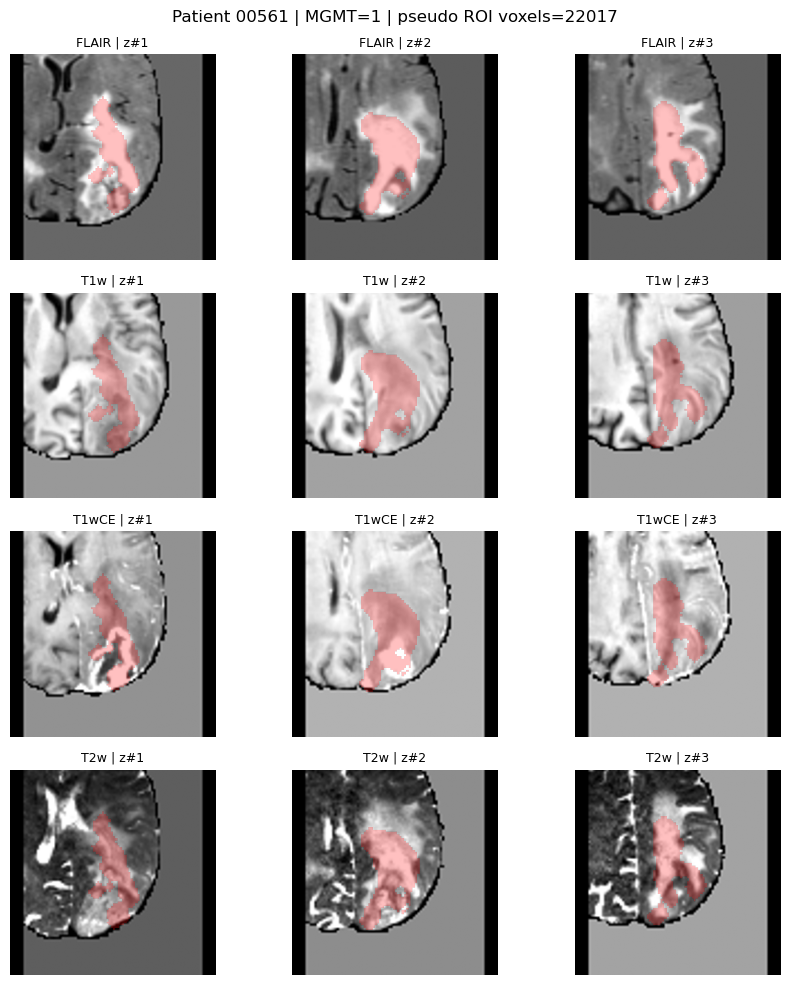

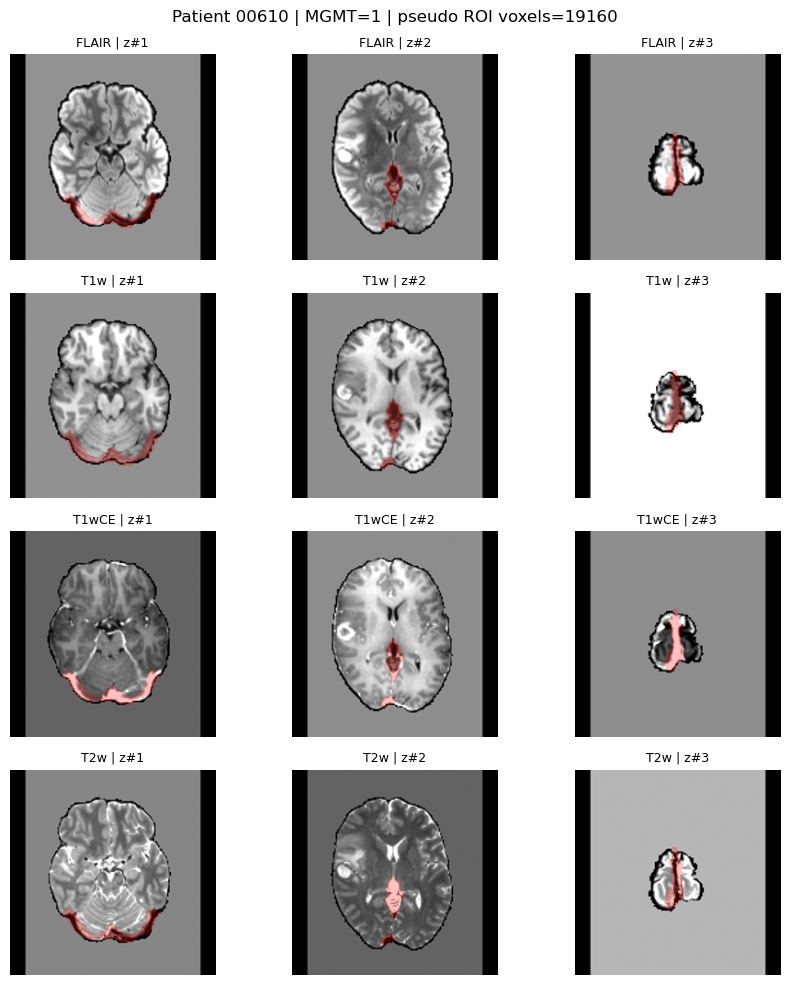

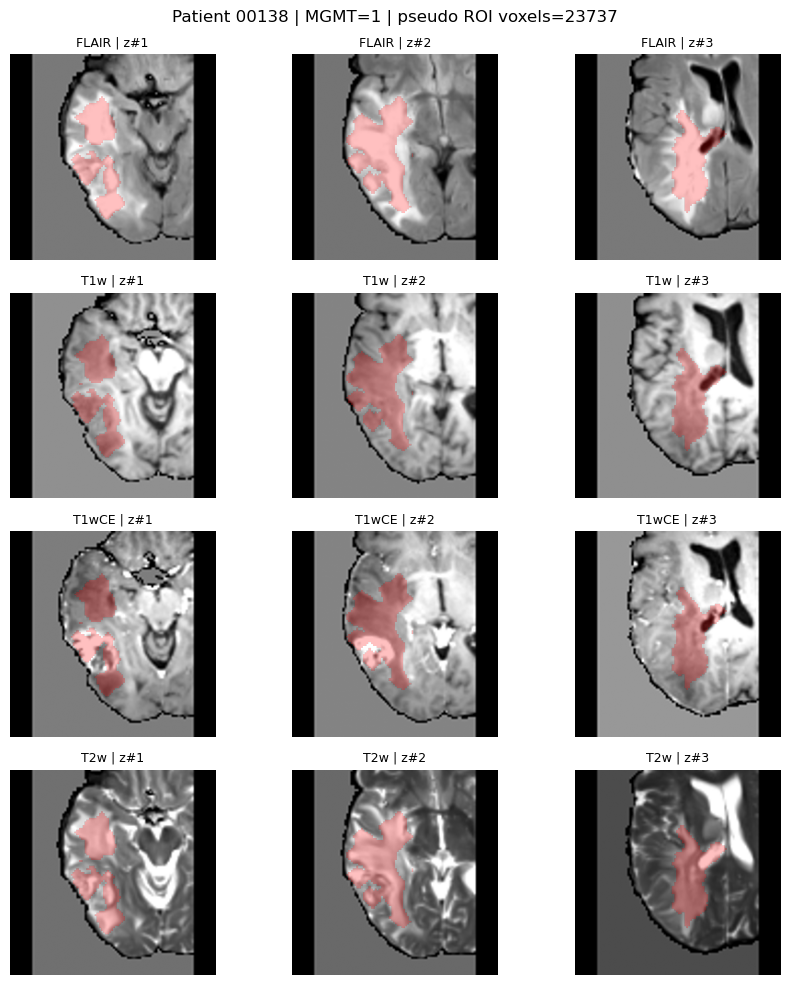

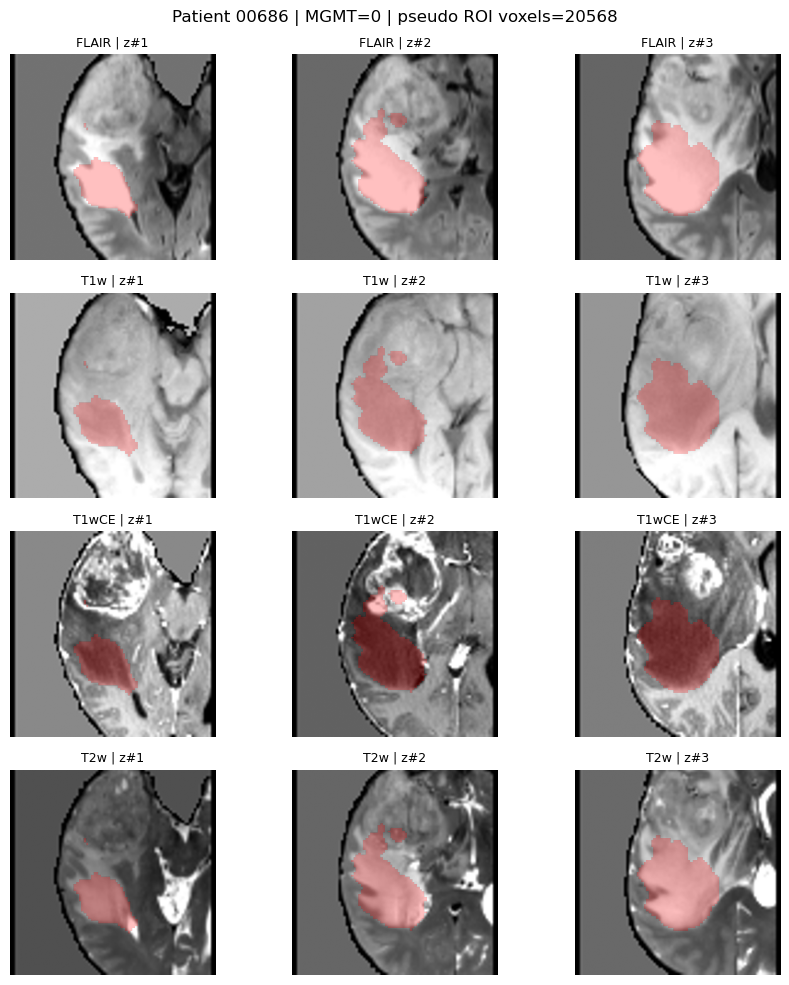

In [9]:
def show_patient_qc(patient_id):
    pid = str(patient_id).zfill(5)
    cache = load_patient_cache(pid)
    tiles = cache["tiles"]
    masks = cache["mask_tiles"]
    meta = cache["metadata"]

    fig, axes = plt.subplots(
        N_MODALITIES,
        SLICES_PER_MODALITY,
        figsize=(9, 10)
    )

    for m in range(N_MODALITIES):
        for s in range(SLICES_PER_MODALITY):
            idx = m * SLICES_PER_MODALITY + s
            ax = axes[m, s]
            ax.imshow(tiles[idx], cmap="gray")

            # Same pseudo ROI for corresponding slice in all modalities.
            mask = np.ma.masked_where(masks[s] == 0, masks[s])
            ax.imshow(mask, cmap="autumn", alpha=0.25)

            ax.axis("off")
            ax.set_title(
                f"{MODALITIES[m]} | z#{s+1}",
                fontsize=9
            )

    y = int(
        labels.loc[labels["BraTS21ID"] == pid, "MGMT_value"].iloc[0]
    )
    fig.suptitle(
        f"Patient {pid} | MGMT={y} | "
        f"pseudo ROI voxels={meta['pseudo_roi_voxels']}"
    )
    plt.tight_layout()
    plt.savefig(
        OUTPUT_DIR / f"QC_{pid}.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()


for pid in labels.sample(
    min(4, len(labels)),
    random_state=SEED
)["BraTS21ID"]:
    show_patient_qc(pid)

## 10. Image Dataset with modality dropout

In [10]:
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


def augment_tiles(tiles, training):
    imgs = [Image.fromarray(t, mode="L") for t in tiles]

    if training:
        if random.random() < 0.5:
            imgs = [ImageOps.mirror(im) for im in imgs]

        angle = random.uniform(-4, 4)
        contrast = random.uniform(0.93, 1.07)
        brightness = random.uniform(0.95, 1.05)

        out = []
        for im in imgs:
            im = im.rotate(
                angle,
                resample=Image.Resampling.BILINEAR,
                fillcolor=0
            )
            im = ImageEnhance.Contrast(im).enhance(contrast)
            im = ImageEnhance.Brightness(im).enhance(brightness)
            out.append(im)
        imgs = out

    return np.stack(
        [np.asarray(im, dtype=np.uint8) for im in imgs],
        axis=0
    )


def tiles_to_tensor(tiles):
    x = torch.from_numpy(
        tiles.astype(np.float32) / 255.0
    ).unsqueeze(1)
    x = x.repeat(1, 3, 1, 1)
    x = (
        x
        - IMAGENET_MEAN.unsqueeze(0)
    ) / IMAGENET_STD.unsqueeze(0)
    return x


def randomly_drop_modalities(x, p=MODALITY_DROPOUT_P):
    if p <= 0 or random.random() >= p:
        return x

    # Drop exactly one modality, never all modalities.
    m = random.randrange(N_MODALITIES)
    start = m * SLICES_PER_MODALITY
    end = start + SLICES_PER_MODALITY
    x = x.clone()
    x[start:end] = 0.0
    return x


class MRIPatientDataset(Dataset):
    def __init__(self, df, training=False, split_name="train", with_labels=True):
        self.df = df.reset_index(drop=True).copy()
        self.training = training
        self.split_name = split_name
        self.with_labels = with_labels

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        pid = str(row["BraTS21ID"]).zfill(5)
        cache = load_patient_cache(pid, self.split_name)

        tiles = augment_tiles(
            cache["tiles"],
            training=self.training
        )
        x = tiles_to_tensor(tiles)

        if self.training:
            x = randomly_drop_modalities(x)

        if self.with_labels:
            y = torch.tensor(
                float(row["MGMT_value"]),
                dtype=torch.float32
            )
            return x, y, pid

        return x, pid


def make_image_loader(
    df,
    training,
    batch_size,
    split_name="train",
    with_labels=True
):
    return DataLoader(
        MRIPatientDataset(
            df,
            training=training,
            split_name=split_name,
            with_labels=with_labels
        ),
        batch_size=batch_size,
        shuffle=training,
        num_workers=NUM_WORKERS,
        pin_memory=True,
        drop_last=False
    )

## 11. Multi-view tumor-focused ViT

In [11]:
class TumorFocusedMultiViewViT(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()

        try:
            self.backbone = timm.create_model(
                VIT_MODEL_NAME,
                pretrained=pretrained,
                num_classes=0
            )
        except Exception:
            self.backbone = timm.create_model(
                "vit_small_patch16_224",
                pretrained=pretrained,
                num_classes=0
            )

        self.feature_dim = int(self.backbone.num_features)

        self.modality_embed = nn.Embedding(
            N_MODALITIES,
            self.feature_dim
        )
        self.slice_embed = nn.Embedding(
            SLICES_PER_MODALITY,
            self.feature_dim
        )

        modality_ids = []
        slice_ids = []

        for m in range(N_MODALITIES):
            for s in range(SLICES_PER_MODALITY):
                modality_ids.append(m)
                slice_ids.append(s)

        self.register_buffer(
            "modality_ids",
            torch.tensor(modality_ids, dtype=torch.long),
            persistent=False
        )
        self.register_buffer(
            "slice_ids",
            torch.tensor(slice_ids, dtype=torch.long),
            persistent=False
        )

        hidden = max(96, self.feature_dim // 3)

        self.view_attention = nn.Sequential(
            nn.Linear(self.feature_dim, hidden),
            nn.Tanh(),
            nn.Dropout(0.10),
            nn.Linear(hidden, 1)
        )

        self.classifier = nn.Sequential(
            nn.LayerNorm(self.feature_dim),
            nn.Dropout(VIT_DROPOUT),
            nn.Linear(self.feature_dim, 160),
            nn.GELU(),
            nn.Dropout(VIT_DROPOUT),
            nn.Linear(160, 1)
        )

    def forward(self, x, return_attention=False):
        B, V, C, H, W = x.shape

        z = self.backbone(
            x.reshape(B * V, C, H, W)
        ).reshape(B, V, self.feature_dim)

        z = (
            z
            + self.modality_embed(self.modality_ids).unsqueeze(0)
            + self.slice_embed(self.slice_ids).unsqueeze(0)
        )

        attn = torch.softmax(
            self.view_attention(z).squeeze(-1),
            dim=1
        )

        pooled = torch.sum(
            z * attn.unsqueeze(-1),
            dim=1
        )

        logits = self.classifier(pooled).squeeze(-1)

        if return_attention:
            return logits, attn
        return logits

## 12. Training / threshold / evaluation utilities

In [12]:
def fixed_threshold_metrics(y_true, probs, threshold=0.5):
    y_true = np.asarray(y_true).astype(int)
    probs = np.asarray(probs, dtype=float)
    pred = (probs >= threshold).astype(int)

    cm = confusion_matrix(y_true, pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    return {
        "roc_auc": roc_auc_score(y_true, probs),
        "pr_auc": average_precision_score(y_true, probs),
        "accuracy": accuracy_score(y_true, pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "sensitivity": recall_score(y_true, pred, zero_division=0),
        "specificity": tn / max(1, tn + fp),
        "f1": f1_score(y_true, pred, zero_division=0),
        "brier": brier_score_loss(y_true, probs),
    }


def choose_balanced_threshold(y_true, probs):
    y_true = np.asarray(y_true).astype(int)
    probs = np.asarray(probs, dtype=float)

    candidates = np.unique(
        np.concatenate([
            np.linspace(0.15, 0.85, 141),
            probs
        ])
    )

    best_t = 0.5
    best_score = -np.inf

    for t in candidates:
        pred = (probs >= t).astype(int)
        score = balanced_accuracy_score(y_true, pred)

        # Mild tie-break toward 0.5.
        adjusted = score - 1e-5 * abs(t - 0.5)

        if adjusted > best_score:
            best_score = adjusted
            best_t = float(t)

    return best_t


def metrics_from_predictions(y_true, probs, pred):
    y_true = np.asarray(y_true).astype(int)
    probs = np.asarray(probs, dtype=float)
    pred = np.asarray(pred).astype(int)

    cm = confusion_matrix(y_true, pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    return {
        "roc_auc": roc_auc_score(y_true, probs),
        "pr_auc": average_precision_score(y_true, probs),
        "accuracy": accuracy_score(y_true, pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "sensitivity": recall_score(y_true, pred, zero_division=0),
        "specificity": tn / max(1, tn + fp),
        "f1": f1_score(y_true, pred, zero_division=0),
        "brier": brier_score_loss(y_true, probs),
    }


def freeze_vit_backbone(model):
    for p in model.backbone.parameters():
        p.requires_grad = False


def unfreeze_vit_tail(model, n_blocks=VIT_UNFREEZE_BLOCKS):
    freeze_vit_backbone(model)

    if hasattr(model.backbone, "blocks"):
        for block in model.backbone.blocks[-n_blocks:]:
            for p in block.parameters():
                p.requires_grad = True

    if hasattr(model.backbone, "norm"):
        for p in model.backbone.norm.parameters():
            p.requires_grad = True


def make_vit_optimizer(model, backbone_lr, head_lr):
    bb, head = [], []

    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        if name.startswith("backbone."):
            bb.append(p)
        else:
            head.append(p)

    groups = []
    if bb:
        groups.append({"params": bb, "lr": backbone_lr})
    if head:
        groups.append({"params": head, "lr": head_lr})

    return torch.optim.AdamW(
        groups,
        weight_decay=1e-4
    )


def bce_loss(logits, targets, pos_weight=None):
    smooth = 0.02
    y = targets * (1 - smooth) + 0.5 * smooth

    return F.binary_cross_entropy_with_logits(
        logits,
        y,
        pos_weight=pos_weight
    )



def train_image_epoch(
    model,
    loader,
    optimizer,
    pos_weight,
    grad_accum_steps=VIT_GRAD_ACCUM_STEPS
):
    """
    Memory-safe mixed-precision training.

    VIT_BATCH_SIZE=1 keeps only 12 MRI views from one patient in memory.
    Gradients are accumulated so the effective batch remains approximately 3.
    """
    model.train()

    scaler = getattr(train_image_epoch, "_scaler", None)
    if scaler is None:
        scaler = torch.cuda.amp.GradScaler(
            enabled=(DEVICE.type == "cuda")
        )
        train_image_epoch._scaler = scaler

    total_loss = 0.0
    total_n = 0

    optimizer.zero_grad(set_to_none=True)

    n_batches = len(loader)

    for step, (x, y, _) in enumerate(tqdm(loader, leave=False), start=1):
        x = x.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        with torch.cuda.amp.autocast(
            enabled=(DEVICE.type == "cuda")
        ):
            logits = model(x)
            raw_loss = bce_loss(
                logits,
                y,
                pos_weight
            )
            loss = raw_loss / max(1, grad_accum_steps)

        scaler.scale(loss).backward()

        do_step = (
            step % max(1, grad_accum_steps) == 0
            or step == n_batches
        )

        if do_step:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                1.0
            )
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

        total_loss += float(raw_loss.detach()) * len(y)
        total_n += len(y)

        # Drop per-batch CUDA references immediately.
        del x, y, logits, raw_loss, loss

    return total_loss / max(1, total_n)


@torch.no_grad()
def predict_image_model(
    model,
    loader,
    tta=USE_TTA,
    return_attention=False
):
    model.eval()

    probs, ys, ids = [], [], []
    attentions = []

    for x, y, batch_ids in loader:
        x = x.to(DEVICE, non_blocking=True)

        if return_attention:
            logits, attn = model(
                x,
                return_attention=True
            )
        else:
            logits = model(x)
            attn = None

        p = torch.sigmoid(logits)

        if tta:
            xf = torch.flip(x, dims=[-1])

            if return_attention:
                lf, af = model(
                    xf,
                    return_attention=True
                )
            else:
                lf = model(xf)
                af = None

            pf = torch.sigmoid(lf)
            p = 0.5 * (p + pf)

            if return_attention:
                attn = 0.5 * (attn + af)

        probs.extend(p.cpu().numpy().tolist())
        ys.extend(y.numpy().tolist())
        ids.extend(list(batch_ids))

        if return_attention:
            attentions.append(attn.cpu().numpy())

    if return_attention:
        return (
            np.asarray(probs),
            np.asarray(ys),
            ids,
            np.concatenate(attentions, axis=0)
        )

    return np.asarray(probs), np.asarray(ys), ids


def save_torch_model(model, path, extra=None):
    payload = {
        "state_dict": model.state_dict()
    }
    if extra:
        payload.update(extra)
    torch.save(payload, path)


def load_vit_model(path):
    model = TumorFocusedMultiViewViT().to(DEVICE)
    ckpt = torch.load(path, map_location=DEVICE)
    model.load_state_dict(ckpt["state_dict"])
    model.eval()
    return model

def aggressive_cuda_cleanup(
    move_biomedclip_to_cpu=False,
    purge_all_cuda_globals=False,
    verbose=True
):
    """
    Aggressively release CUDA memory between stages/folds.

    Why this is necessary:
    - optimizers keep references to model parameters even after `del model`
    - rerunning Kaggle cells can leave old GPU objects in global variables
    - BiomedCLIP and prior XAI/model objects can occupy several GB

    `purge_all_cuda_globals=True` is used before the first ViT fold. At that
    point no GPU model/tensor is required, so stale CUDA objects from a
    previous notebook run can safely be removed.
    """
    g = globals()

    # Move BiomedCLIP off GPU when requested.
    if move_biomedclip_to_cpu and "vlm_model" in g:
        try:
            if isinstance(g["vlm_model"], nn.Module):
                g["vlm_model"] = g["vlm_model"].to("cpu")
        except Exception:
            pass

    # Explicit names commonly left alive by notebook loops.
    stale_names = [
        "model", "adapter", "FINAL_VIT", "FINAL_VLM_ADAPTER",
        "opt", "optimizer", "scheduler", "pos_weight",
        "train_loader", "stop_loader", "outer_loader", "full_loader",
        "test_loader", "x", "xf", "logits", "loss",
        "cam", "campp", "gc_result", "gcpp_result",
    ]

    for name in stale_names:
        if name in g:
            try:
                obj = g[name]
                if isinstance(obj, nn.Module):
                    try:
                        obj.to("cpu")
                    except Exception:
                        pass
                del g[name]
            except Exception:
                pass

    # On reruns, remove ANY stale top-level CUDA module/tensor/optimizer.
    if purge_all_cuda_globals:
        protected = {
            "DEVICE", "IMAGENET_MEAN", "IMAGENET_STD",
            "TEXT_FEATURES",  # may not exist yet; harmless
        }

        for name, obj in list(g.items()):
            if name in protected or name.startswith("__"):
                continue

            try:
                if isinstance(obj, nn.Module):
                    has_cuda_param = any(
                        p.is_cuda for p in obj.parameters(recurse=True)
                    )
                    if has_cuda_param:
                        try:
                            obj.to("cpu")
                        except Exception:
                            pass
                        try:
                            del g[name]
                        except Exception:
                            pass

                elif isinstance(obj, torch.Tensor) and obj.is_cuda:
                    try:
                        del g[name]
                    except Exception:
                        pass

                elif isinstance(obj, torch.optim.Optimizer):
                    try:
                        del g[name]
                    except Exception:
                        pass
            except Exception:
                pass

    gc.collect()

    if torch.cuda.is_available():
        try:
            torch.cuda.synchronize()
        except Exception:
            pass

        torch.cuda.empty_cache()

        try:
            torch.cuda.ipc_collect()
        except Exception:
            pass

        gc.collect()
        torch.cuda.empty_cache()

        free_b, total_b = torch.cuda.mem_get_info()

        if verbose:
            print(
                f"CUDA memory after cleanup: "
                f"{free_b/1024**3:.2f} GiB free / "
                f"{total_b/1024**3:.2f} GiB total"
            )

        return free_b, total_b

    return None, None


def ensure_gpu_memory(min_free_gib=6.0, stage="training"):
    """
    Clean stale notebook state and verify enough free GPU RAM before a model
    is created. This catches the exact failure seen in the uploaded run.
    """
    if not torch.cuda.is_available():
        return

    free_b, total_b = aggressive_cuda_cleanup(
        purge_all_cuda_globals=True,
        verbose=True
    )

    free_gib = free_b / 1024**3
    if free_gib < min_free_gib:
        raise RuntimeError(
            f"Only {free_gib:.2f} GiB CUDA memory is free before {stage}. "
            "The Kaggle kernel still contains live GPU objects from an older run. "
            "Use 'Restart Session' once, then Run All from the top. "
            "The corrected notebook will prevent the leak on subsequent folds."
        )

## 13. Common 5-fold outer split using every usable patient

In [13]:
labels = labels.reset_index(drop=True)
y_all = labels["MGMT_value"].astype(int).values

skf = StratifiedKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=SEED
)

folds = []
fold_assignment = np.full(len(labels), -1, dtype=int)

for fold, (tr, va) in enumerate(skf.split(labels, y_all)):
    folds.append((tr, va))
    fold_assignment[va] = fold

labels["outer_fold"] = fold_assignment
labels.to_csv(
    OUTPUT_DIR / "all_patient_folds.csv",
    index=False
)

print(labels["outer_fold"].value_counts().sort_index())

outer_fold
0    117
1    117
2    117
3    117
4    117
Name: count, dtype: int64


## 14. 5-fold tumor-focused ViT OOF training

In [14]:

# HARD RESET BEFORE THE FIRST OOF MODEL.
# This makes the notebook safe even if Kaggle retained GPU objects from a
# previous run in the same kernel.
ensure_gpu_memory(
    min_free_gib=6.0,
    stage="ViT cross-validation"
)

vit_oof = np.full(len(labels), np.nan)
vit_oof_pred_tuned = np.full(len(labels), -1, dtype=int)
vit_fold_thresholds = {}
vit_best_epochs = []
vit_attention_oof = np.full((len(labels), N_VIEWS), np.nan)
vit_history = []

for fold, (outer_train_idx, outer_val_idx) in enumerate(folds):
    print("\n" + "=" * 80)
    print(f"ViT FOLD {fold+1}/{N_FOLDS}")
    print("=" * 80)

    # Critical: remove optimizer/model references left by the previous fold.
    aggressive_cuda_cleanup(
        purge_all_cuda_globals=False,
        verbose=False
    )

    outer_train_df = labels.iloc[outer_train_idx].copy()
    outer_val_df = labels.iloc[outer_val_idx].copy()

    inner_train_df, inner_stop_df = train_test_split(
        outer_train_df,
        test_size=INNER_VAL_FRAC,
        stratify=outer_train_df["MGMT_value"],
        random_state=SEED + fold
    )

    train_loader = make_image_loader(
        inner_train_df,
        True,
        VIT_BATCH_SIZE
    )
    stop_loader = make_image_loader(
        inner_stop_df,
        False,
        VIT_BATCH_SIZE
    )
    outer_loader = make_image_loader(
        outer_val_df,
        False,
        VIT_BATCH_SIZE
    )

    model = TumorFocusedMultiViewViT().to(DEVICE)

    n_pos = int((inner_train_df["MGMT_value"] == 1).sum())
    n_neg = int((inner_train_df["MGMT_value"] == 0).sum())
    pos_weight = torch.tensor(
        [n_neg / max(1, n_pos)],
        dtype=torch.float32,
        device=DEVICE
    )

    ckpt_path = MODEL_DIR / f"vit_fold_{fold}.pt"

    # Warm up attention/head.
    freeze_vit_backbone(model)
    opt = make_vit_optimizer(
        model,
        backbone_lr=0.0,
        head_lr=VIT_HEAD_LR
    )

    for epoch in range(VIT_HEAD_EPOCHS):
        loss = train_image_epoch(
            model,
            train_loader,
            opt,
            pos_weight
        )
        p_stop, y_stop, _ = predict_image_model(
            model,
            stop_loader,
            tta=False
        )
        print(
            f"warmup {epoch+1}: loss={loss:.4f}, "
            f"inner AUC={roc_auc_score(y_stop, p_stop):.4f}"
        )

    # Partial fine-tune.
    unfreeze_vit_tail(model)
    opt = make_vit_optimizer(
        model,
        backbone_lr=VIT_BACKBONE_LR,
        head_lr=VIT_FINETUNE_HEAD_LR
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        opt,
        T_max=max(1, VIT_FINETUNE_EPOCHS),
        eta_min=VIT_BACKBONE_LR * 0.1
    )

    best_auc = -np.inf
    best_epoch = 0
    best_threshold = 0.5
    bad_epochs = 0

    for epoch in range(1, VIT_FINETUNE_EPOCHS + 1):
        loss = train_image_epoch(
            model,
            train_loader,
            opt,
            pos_weight
        )

        p_stop, y_stop, _ = predict_image_model(
            model,
            stop_loader,
            tta=False
        )

        stop_auc = roc_auc_score(
            y_stop,
            p_stop
        )
        stop_threshold = choose_balanced_threshold(
            y_stop,
            p_stop
        )

        vit_history.append({
            "fold": fold,
            "epoch": epoch,
            "loss": loss,
            "inner_auc": stop_auc,
            "inner_threshold": stop_threshold
        })

        print(
            f"epoch {epoch}/{VIT_FINETUNE_EPOCHS}: "
            f"loss={loss:.4f}, inner AUC={stop_auc:.4f}, "
            f"threshold={stop_threshold:.3f}"
        )

        if stop_auc > best_auc + 1e-5:
            best_auc = stop_auc
            best_epoch = epoch
            best_threshold = stop_threshold
            bad_epochs = 0

            save_torch_model(
                model,
                ckpt_path,
                extra={
                    "threshold": best_threshold,
                    "best_epoch": best_epoch
                }
            )
        else:
            bad_epochs += 1

        scheduler.step()

        if bad_epochs >= VIT_PATIENCE:
            break

    vit_best_epochs.append(best_epoch)
    vit_fold_thresholds[fold] = best_threshold

    model = load_vit_model(ckpt_path)

    p_outer, y_outer, ids_outer, attn_outer = predict_image_model(
        model,
        outer_loader,
        tta=USE_TTA,
        return_attention=True
    )

    vit_oof[outer_val_idx] = p_outer
    vit_oof_pred_tuned[outer_val_idx] = (
        p_outer >= best_threshold
    ).astype(int)
    vit_attention_oof[outer_val_idx] = attn_outer

    print(
        "Outer AUC:",
        roc_auc_score(y_outer, p_outer)
    )

    # Optimizers/schedulers hold model parameter references.
    # Delete them explicitly or GPU memory leaks across CV folds.
    try:
        del model, opt, scheduler, pos_weight
    except Exception:
        pass
    try:
        del train_loader, stop_loader, outer_loader
    except Exception:
        pass

    aggressive_cuda_cleanup(
        purge_all_cuda_globals=False,
        verbose=True
    )

pd.DataFrame(vit_history).to_csv(
    OUTPUT_DIR / "vit_training_history.csv",
    index=False
)
np.save(OUTPUT_DIR / "vit_oof.npy", vit_oof)
np.save(
    OUTPUT_DIR / "vit_attention_oof.npy",
    vit_attention_oof
)

print("\nViT OOF @ 0.5")
print(fixed_threshold_metrics(y_all, vit_oof, 0.5))

print("\nViT OOF with nested fold thresholds")
print(metrics_from_predictions(
    y_all,
    vit_oof,
    vit_oof_pred_tuned
))

print("Thresholds:", vit_fold_thresholds)

CUDA memory after cleanup: 30.23 GiB free / 31.84 GiB total

ViT FOLD 1/5


model.safetensors: reconstructing file:   0%|          |  0.00B / 86.7MB            

model.safetensors: downloading bytes:           |  0.00B            

  0%|          | 0/374 [00:00<?, ?it/s]

warmup 1: loss=0.6962, inner AUC=0.5170


...

epoch 4/6: loss=0.6308, inner AUC=0.6635, threshold=0.439


  0%|          | 0/374 [00:00<?, ?it/s]

epoch 5/6: loss=0.5551, inner AUC=0.6707, threshold=0.715


  0%|          | 0/374 [00:00<?, ?it/s]

epoch 6/6: loss=0.4813, inner AUC=0.6694, threshold=0.396
Outer AUC: 0.548887587822014
CUDA memory after cleanup: 30.09 GiB free / 31.84 GiB total

ViT OOF @ 0.5
{'roc_auc': 0.550312844187191, 'pr_auc': 0.57521335550254, 'accuracy': 0.5299145299145299, 'balanced_accuracy': 0.5291812152883557, 'precision': 0.5529801324503312, 'sensitivity': 0.5439739413680782, 'specificity': np.float64(0.5143884892086331), 'f1': 0.548440065681445, 'brier': 0.27258324118078986}

ViT OOF with nested fold thresholds
{'roc_auc': 0.550312844187191, 'pr_auc': 0.57521335550254, 'accuracy': 0.5264957264957265, 'balanced_accuracy': 0.5237152297705809, 'precision': 0.5460122699386503, 'sensitivity': 0.5798045602605864, 'specificity': np.float64(0.4676258992805755), 'f1': 0.5624012638230648, 'brier': 0.27258324118078986}
Thresholds: {0: 0.46925127506256104, 1: 0.4849371016025543, 2: 0.497494101524353, 3: 0.1385258436203003, 4: 0.7150000000000001}


## 15. Load BiomedCLIP and extract all per-view embeddings

In [15]:
aggressive_cuda_cleanup(
    purge_all_cuda_globals=False,
    verbose=True
)

vlm_model, _, vlm_preprocess = open_clip.create_model_and_transforms(
    BIOMEDCLIP_NAME
)
vlm_tokenizer = open_clip.get_tokenizer(
    BIOMEDCLIP_NAME
)

vlm_model = vlm_model.to(DEVICE).eval()
for p in vlm_model.parameters():
    p.requires_grad = False

PROMPTS = {
    0: [
        "brain MRI of glioblastoma with unmethylated MGMT promoter",
        "glioblastoma magnetic resonance imaging associated with unmethylated MGMT promoter",
        "MRI appearance of an MGMT promoter unmethylated glioblastoma",
    ],
    1: [
        "brain MRI of glioblastoma with methylated MGMT promoter",
        "glioblastoma magnetic resonance imaging associated with methylated MGMT promoter",
        "MRI appearance of an MGMT promoter methylated glioblastoma",
    ]
}


@torch.no_grad()
def prompt_features():
    out = []
    for cls in [0, 1]:
        tokens = vlm_tokenizer(PROMPTS[cls]).to(DEVICE)
        f = vlm_model.encode_text(tokens)
        f = f / f.norm(dim=-1, keepdim=True)
        f = f.mean(dim=0, keepdim=True)
        f = f / f.norm(dim=-1, keepdim=True)
        out.append(f)
    return torch.cat(out, dim=0)


TEXT_FEATURES = prompt_features()


class VLMEmbeddingDataset(Dataset):
    def __init__(self, df, split_name="train", with_labels=True):
        self.df = df.reset_index(drop=True).copy()
        self.split_name = split_name
        self.with_labels = with_labels

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        pid = str(row["BraTS21ID"]).zfill(5)
        tiles = load_patient_cache(pid, self.split_name)["tiles"]

        xs = []
        for tile in tiles:
            pil = Image.fromarray(tile, mode="L").convert("RGB")
            xs.append(vlm_preprocess(pil))
        x = torch.stack(xs)

        if self.with_labels:
            return x, int(row["MGMT_value"]), pid
        return x, pid


@torch.no_grad()
def extract_vlm_embeddings(df, split_name="train", with_labels=True):
    loader = DataLoader(
        VLMEmbeddingDataset(
            df,
            split_name=split_name,
            with_labels=with_labels
        ),
        batch_size=VLM_BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True
    )

    all_e = []
    all_prompt = []
    all_y = []
    all_ids = []

    for batch in tqdm(loader, desc="BiomedCLIP embeddings"):
        if with_labels:
            x, y, ids = batch
            all_y.extend(y.numpy().tolist())
        else:
            x, ids = batch

        B, V, C, H, W = x.shape
        x = x.to(DEVICE).reshape(B * V, C, H, W)

        e = vlm_model.encode_image(x)
        e = e / e.norm(dim=-1, keepdim=True)
        e = e.reshape(B, V, -1)

        logits = 100.0 * torch.einsum(
            "bvd,cd->bvc",
            e,
            TEXT_FEATURES
        )
        prompt_prob = torch.softmax(
            logits,
            dim=-1
        )[:, :, 1]

        all_e.append(e.cpu().numpy())
        all_prompt.append(prompt_prob.cpu().numpy())
        all_ids.extend(list(ids))

    E = np.concatenate(all_e, axis=0)
    P = np.concatenate(all_prompt, axis=0)

    if with_labels:
        return (
            E,
            P,
            np.asarray(all_y),
            all_ids
        )
    return E, P, all_ids


VLM_E, VLM_PROMPT, vlm_y, vlm_ids = extract_vlm_embeddings(
    labels
)

assert list(labels["BraTS21ID"].astype(str)) == list(map(str, vlm_ids))

np.save(
    OUTPUT_DIR / "biomedclip_view_embeddings.npy",
    VLM_E
)
np.save(
    OUTPUT_DIR / "biomedclip_prompt_probs.npy",
    VLM_PROMPT
)

print("Embedding shape:", VLM_E.shape)
print("Prompt shape:", VLM_PROMPT.shape)

# BiomedCLIP embeddings are now NumPy arrays. The large encoder is not needed
# on GPU during adapter CV / SVM / stacking / XAI.
try:
    vlm_model = vlm_model.to("cpu")
    TEXT_FEATURES = TEXT_FEATURES.to("cpu")
except Exception:
    pass

aggressive_cuda_cleanup(
    move_biomedclip_to_cpu=True,
    purge_all_cuda_globals=False,
    verbose=True
)


CUDA memory after cleanup: 30.09 GiB free / 31.84 GiB total


open_clip_config.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

open_clip_pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  784MB            

open_clip_pytorch_model.bin: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/225k [00:00<?, ?B/s]

BiomedCLIP embeddings:   0%|          | 0/147 [00:00<?, ?it/s]

Embedding shape: (585, 12, 512)
Prompt shape: (585, 12)
CUDA memory after cleanup: 30.09 GiB free / 31.84 GiB total


(32307675136, 34190458880)

## 16. Nested modality-subset selection for the VLM branch

In [16]:
MODALITY_TO_INDEX = {
    m: i for i, m in enumerate(MODALITIES)
}


def view_indices_for_modalities(modality_names):
    idxs = []
    for m in modality_names:
        m_idx = MODALITY_TO_INDEX[m]
        start = m_idx * SLICES_PER_MODALITY
        idxs.extend(
            range(start, start + SLICES_PER_MODALITY)
        )
    return np.array(idxs, dtype=int)


def aggregate_embeddings_for_subset(E, P, modality_names):
    idx = view_indices_for_modalities(modality_names)

    e = E[:, idx, :]
    p = P[:, idx]

    # Lightweight subset feature for nested selection.
    return np.concatenate([
        e.mean(axis=1),
        e.max(axis=1),
        p.mean(axis=1, keepdims=True),
        p.max(axis=1, keepdims=True)
    ], axis=1)


def select_best_modality_subset(
    train_indices,
    E,
    P,
    y
):
    best_name = None
    best_auc = -np.inf
    scores = {}

    cv = StratifiedKFold(
        n_splits=3,
        shuffle=True,
        random_state=SEED
    )

    for name, modalities in MODALITY_SUBSETS.items():
        X = aggregate_embeddings_for_subset(
            E[train_indices],
            P[train_indices],
            modalities
        )
        yy = y[train_indices]

        pipe = Pipeline([
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(
                class_weight="balanced",
                C=0.1,
                max_iter=2000,
                random_state=SEED
            ))
        ])

        oof = cross_val_predict(
            pipe,
            X,
            yy,
            cv=cv,
            method="predict_proba",
            n_jobs=-1
        )[:, 1]

        auc = roc_auc_score(yy, oof)
        scores[name] = auc

        if auc > best_auc:
            best_auc = auc
            best_name = name

    return best_name, scores

## 17. BiomedCLIP attention adapter

In [17]:
class VLMAdapter(nn.Module):
    def __init__(self, embed_dim, allowed_modalities):
        super().__init__()
        self.embed_dim = embed_dim

        self.proj = nn.Sequential(
            nn.Linear(embed_dim, VLM_HIDDEN),
            nn.GELU(),
            nn.LayerNorm(VLM_HIDDEN),
            nn.Dropout(0.20)
        )

        self.modality_embed = nn.Embedding(
            N_MODALITIES,
            VLM_HIDDEN
        )
        self.slice_embed = nn.Embedding(
            SLICES_PER_MODALITY,
            VLM_HIDDEN
        )

        modality_ids = []
        slice_ids = []
        allowed = []

        for m_idx, modality in enumerate(MODALITIES):
            for s in range(SLICES_PER_MODALITY):
                modality_ids.append(m_idx)
                slice_ids.append(s)
                allowed.append(
                    1 if modality in allowed_modalities else 0
                )

        self.register_buffer(
            "modality_ids",
            torch.tensor(modality_ids, dtype=torch.long),
            persistent=False
        )
        self.register_buffer(
            "slice_ids",
            torch.tensor(slice_ids, dtype=torch.long),
            persistent=False
        )
        self.register_buffer(
            "allowed_views",
            torch.tensor(allowed, dtype=torch.bool),
            persistent=False
        )

        self.attn = nn.Sequential(
            nn.Linear(VLM_HIDDEN + 1, 96),
            nn.Tanh(),
            nn.Linear(96, 1)
        )

        self.classifier = nn.Sequential(
            nn.Linear(VLM_HIDDEN + 2, 96),
            nn.GELU(),
            nn.Dropout(0.25),
            nn.Linear(96, 1)
        )

    def forward(self, E, prompt_prob, return_attention=False):
        # E [B,12,D], P [B,12]
        h = self.proj(E)
        h = (
            h
            + self.modality_embed(self.modality_ids).unsqueeze(0)
            + self.slice_embed(self.slice_ids).unsqueeze(0)
        )

        attn_input = torch.cat(
            [h, prompt_prob.unsqueeze(-1)],
            dim=-1
        )

        logits = self.attn(attn_input).squeeze(-1)

        # Mask excluded modalities.
        logits = logits.masked_fill(
            ~self.allowed_views.unsqueeze(0),
            -1e4
        )

        attn = torch.softmax(logits, dim=1)
        pooled = torch.sum(
            h * attn.unsqueeze(-1),
            dim=1
        )

        allowed_p = prompt_prob[:, self.allowed_views]
        prompt_summary = torch.stack([
            allowed_p.mean(dim=1),
            allowed_p.max(dim=1).values
        ], dim=1)

        out = self.classifier(
            torch.cat([pooled, prompt_summary], dim=1)
        ).squeeze(-1)

        if return_attention:
            return out, attn
        return out


class VLMArrayDataset(Dataset):
    def __init__(self, indices, E, P, y=None):
        self.indices = np.asarray(indices)
        self.E = E
        self.P = P
        self.y = y

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        idx = int(self.indices[i])

        e = torch.tensor(
            self.E[idx],
            dtype=torch.float32
        )
        p = torch.tensor(
            self.P[idx],
            dtype=torch.float32
        )

        if self.y is None:
            return e, p, idx

        yy = torch.tensor(
            float(self.y[idx]),
            dtype=torch.float32
        )
        return e, p, yy, idx


def make_vlm_loader(indices, E, P, y, training):
    return DataLoader(
        VLMArrayDataset(indices, E, P, y),
        batch_size=32,
        shuffle=training,
        num_workers=0
    )


def train_vlm_epoch(model, loader, optimizer, pos_weight):
    model.train()
    total = 0.0
    n = 0

    for E, P, y, _ in loader:
        E = E.to(DEVICE)
        P = P.to(DEVICE)
        y = y.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        logits = model(E, P)
        loss = bce_loss(
            logits,
            y,
            pos_weight
        )
        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            1.0
        )
        optimizer.step()

        total += float(loss.detach()) * len(y)
        n += len(y)

    return total / max(1, n)


@torch.no_grad()
def predict_vlm_adapter(model, loader, return_attention=False):
    model.eval()

    probs, ys, idxs = [], [], []
    attns = []

    for E, P, y, batch_idx in loader:
        E = E.to(DEVICE)
        P = P.to(DEVICE)

        if return_attention:
            logits, attn = model(
                E, P,
                return_attention=True
            )
            attns.append(attn.cpu().numpy())
        else:
            logits = model(E, P)

        probs.extend(
            torch.sigmoid(logits).cpu().numpy().tolist()
        )
        ys.extend(y.numpy().tolist())
        idxs.extend(batch_idx.numpy().tolist())

    if return_attention:
        return (
            np.asarray(probs),
            np.asarray(ys),
            np.asarray(idxs),
            np.concatenate(attns, axis=0)
        )

    return (
        np.asarray(probs),
        np.asarray(ys),
        np.asarray(idxs)
    )

## 18. 5-fold VLM adapter OOF training with nested modality selection

In [18]:
vlm_oof = np.full(len(labels), np.nan)
vlm_oof_pred_tuned = np.full(len(labels), -1, dtype=int)
vlm_fold_thresholds = {}
vlm_selected_subsets = {}
vlm_best_epochs = []
vlm_attention_oof = np.full((len(labels), N_VIEWS), np.nan)

for fold, (outer_train_idx, outer_val_idx) in enumerate(folds):
    print("\n" + "=" * 80)
    print(f"VLM FOLD {fold+1}/{N_FOLDS}")
    print("=" * 80)

    subset_name, subset_scores = select_best_modality_subset(
        outer_train_idx,
        VLM_E,
        VLM_PROMPT,
        y_all
    )
    selected_modalities = MODALITY_SUBSETS[subset_name]
    vlm_selected_subsets[fold] = subset_name

    print("Nested modality scores:", subset_scores)
    print("Selected subset:", subset_name, selected_modalities)

    aggressive_cuda_cleanup(
        purge_all_cuda_globals=False,
        verbose=False
    )

    # Inner stop split inside outer training.
    inner_train_idx, inner_stop_idx = train_test_split(
        outer_train_idx,
        test_size=INNER_VAL_FRAC,
        stratify=y_all[outer_train_idx],
        random_state=SEED + 500 + fold
    )

    train_loader = make_vlm_loader(
        inner_train_idx,
        VLM_E,
        VLM_PROMPT,
        y_all,
        True
    )
    stop_loader = make_vlm_loader(
        inner_stop_idx,
        VLM_E,
        VLM_PROMPT,
        y_all,
        False
    )
    outer_loader = make_vlm_loader(
        outer_val_idx,
        VLM_E,
        VLM_PROMPT,
        y_all,
        False
    )

    model = VLMAdapter(
        embed_dim=VLM_E.shape[-1],
        allowed_modalities=selected_modalities
    ).to(DEVICE)

    n_pos = int(y_all[inner_train_idx].sum())
    n_neg = int(len(inner_train_idx) - n_pos)
    pos_weight = torch.tensor(
        [n_neg / max(1, n_pos)],
        dtype=torch.float32,
        device=DEVICE
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=VLM_ADAPTER_LR,
        weight_decay=1e-4
    )

    ckpt = MODEL_DIR / f"vlm_adapter_fold_{fold}.pt"

    best_auc = -np.inf
    best_threshold = 0.5
    best_epoch = 1
    bad = 0

    for epoch in range(1, VLM_ADAPTER_EPOCHS + 1):
        loss = train_vlm_epoch(
            model,
            train_loader,
            optimizer,
            pos_weight
        )

        p_stop, y_stop, _ = predict_vlm_adapter(
            model,
            stop_loader
        )

        auc = roc_auc_score(y_stop, p_stop)
        threshold = choose_balanced_threshold(
            y_stop,
            p_stop
        )

        print(
            f"epoch {epoch}: loss={loss:.4f}, "
            f"inner AUC={auc:.4f}, threshold={threshold:.3f}"
        )

        if auc > best_auc + 1e-5:
            best_auc = auc
            best_threshold = threshold
            best_epoch = epoch
            bad = 0

            torch.save({
                "state_dict": model.state_dict(),
                "subset_name": subset_name,
                "selected_modalities": selected_modalities,
                "threshold": best_threshold,
                "best_epoch": best_epoch,
                "embed_dim": int(VLM_E.shape[-1])
            }, ckpt)
        else:
            bad += 1

        if bad >= VLM_ADAPTER_PATIENCE:
            break

    vlm_best_epochs.append(best_epoch)
    vlm_fold_thresholds[fold] = best_threshold

    saved = torch.load(ckpt, map_location=DEVICE)
    model = VLMAdapter(
        embed_dim=VLM_E.shape[-1],
        allowed_modalities=saved["selected_modalities"]
    ).to(DEVICE)
    model.load_state_dict(saved["state_dict"])
    model.eval()

    p_outer, y_outer, idx_outer, attn_outer = predict_vlm_adapter(
        model,
        outer_loader,
        return_attention=True
    )

    # outer_loader preserves outer_val_idx ordering because shuffle=False.
    vlm_oof[outer_val_idx] = p_outer
    vlm_oof_pred_tuned[outer_val_idx] = (
        p_outer >= best_threshold
    ).astype(int)
    vlm_attention_oof[outer_val_idx] = attn_outer

    print("Outer AUC:", roc_auc_score(y_outer, p_outer))

    try:
        del model, optimizer, pos_weight
    except Exception:
        pass
    try:
        del train_loader, stop_loader, outer_loader
    except Exception:
        pass

    aggressive_cuda_cleanup(
        purge_all_cuda_globals=False,
        verbose=True
    )

np.save(OUTPUT_DIR / "vlm_adapter_oof.npy", vlm_oof)
np.save(
    OUTPUT_DIR / "vlm_adapter_attention_oof.npy",
    vlm_attention_oof
)

print("\nVLM adapter @ 0.5")
print(fixed_threshold_metrics(y_all, vlm_oof, 0.5))

print("\nVLM adapter nested thresholds")
print(metrics_from_predictions(
    y_all,
    vlm_oof,
    vlm_oof_pred_tuned
))

print("Selected subsets:", vlm_selected_subsets)


VLM FOLD 1/5
Nested modality scores: {'FLAIR': 0.5418962203715567, 'T2': 0.5478722430676306, 'T1CE': 0.511521918184314, 'FLAIR+T2': 0.5125469021689393, 'FLAIR+T1+T2': 0.49508556785943075, 'FLAIR+T1CE': 0.5051706781367254, 'ALL4': 0.47985723437357003}
Selected subset: T2 ['T2w']
epoch 1: loss=0.6687, inner AUC=0.4717, threshold=0.493
epoch 2: loss=0.6624, inner AUC=0.4712, threshold=0.498
epoch 3: loss=0.6597, inner AUC=0.5365, threshold=0.496
epoch 4: loss=0.6557, inner AUC=0.5293, threshold=0.472
epoch 5: loss=0.6432, inner AUC=0.5234, threshold=0.448
epoch 6: loss=0.6539, inner AUC=0.5224, threshold=0.505
Outer AUC: 0.5237536656891496
CUDA memory after cleanup: 30.09 GiB free / 31.84 GiB total

VLM FOLD 2/5
Nested modality scores: {'FLAIR': 0.5306671547542784, 'T2': 0.5202251304109087, 'T1CE': 0.4861352612793996, 'FLAIR+T2': 0.5340715658460694, 'FLAIR+T1+T2': 0.4871419419785852, 'FLAIR+T1CE': 0.5484396449162625, 'ALL4': 0.4882218358195296}
Selected subset: FLAIR+T1CE ['FLAIR', 'T1wC

## 19. Quantitative pseudo-ROI feature matrix

In [19]:
feature_cols = [
    c for c in quant_df.columns
    if c not in ["BraTS21ID", "MGMT_value"]
]

X_quant = quant_df[feature_cols].replace(
    [np.inf, -np.inf],
    np.nan
).values.astype(np.float32)

y_quant = quant_df["MGMT_value"].astype(int).values

assert np.array_equal(y_quant, y_all)

print("Quantitative feature matrix:", X_quant.shape)

Quantitative feature matrix: (585, 188)


## 20. 5-fold quantitative-feature SVM with nested hyperparameter selection

In [20]:
quant_oof = np.full(len(labels), np.nan)
quant_oof_pred_tuned = np.full(len(labels), -1, dtype=int)
quant_fold_thresholds = {}
quant_fold_models = {}

for fold, (outer_train_idx, outer_val_idx) in enumerate(folds):
    print("\nQuantitative feature fold", fold + 1)

    n_features = X_quant.shape[1]
    k_options = [
        min(20, n_features),
        min(40, n_features),
        "all"
    ]

    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("select", SelectKBest(
            mutual_info_classif,
            k="all"
        )),
        ("svc", SVC(
            probability=True,
            class_weight="balanced",
            random_state=SEED
        ))
    ])

    grid = GridSearchCV(
        pipeline,
        param_grid={
            "select__k": k_options,
            "svc__C": [0.1, 1.0, 10.0],
            "svc__gamma": ["scale", 0.01, 0.001],
        },
        scoring="roc_auc",
        cv=StratifiedKFold(
            n_splits=3,
            shuffle=True,
            random_state=SEED + fold
        ),
        n_jobs=-1,
        refit=True
    )

    grid.fit(
        X_quant[outer_train_idx],
        y_all[outer_train_idx]
    )

    best = grid.best_estimator_

    # Get training-only OOF predictions to choose the operating threshold.
    train_oof_prob = cross_val_predict(
        best,
        X_quant[outer_train_idx],
        y_all[outer_train_idx],
        cv=StratifiedKFold(
            n_splits=3,
            shuffle=True,
            random_state=SEED + 1000 + fold
        ),
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    threshold = choose_balanced_threshold(
        y_all[outer_train_idx],
        train_oof_prob
    )

    p_outer = best.predict_proba(
        X_quant[outer_val_idx]
    )[:, 1]

    quant_oof[outer_val_idx] = p_outer
    quant_oof_pred_tuned[outer_val_idx] = (
        p_outer >= threshold
    ).astype(int)
    quant_fold_thresholds[fold] = threshold
    quant_fold_models[fold] = best

    joblib.dump(
        best,
        MODEL_DIR / f"quant_svm_fold_{fold}.joblib"
    )

    print(
        "Best params:",
        grid.best_params_,
        "| threshold:",
        round(threshold, 3),
        "| outer AUC:",
        round(
            roc_auc_score(
                y_all[outer_val_idx],
                p_outer
            ),
            4
        )
    )

np.save(OUTPUT_DIR / "quant_oof.npy", quant_oof)

print("\nQuantitative model @ 0.5")
print(fixed_threshold_metrics(y_all, quant_oof, 0.5))

print("\nQuantitative model nested thresholds")
print(metrics_from_predictions(
    y_all,
    quant_oof,
    quant_oof_pred_tuned
))


Quantitative feature fold 1
Best params: {'select__k': 'all', 'svc__C': 1.0, 'svc__gamma': 'scale'} | threshold: 0.482 | outer AUC: 0.5226

Quantitative feature fold 2
Best params: {'select__k': 'all', 'svc__C': 1.0, 'svc__gamma': 'scale'} | threshold: 0.5 | outer AUC: 0.4771

Quantitative feature fold 3
Best params: {'select__k': 40, 'svc__C': 10.0, 'svc__gamma': 0.01} | threshold: 0.534 | outer AUC: 0.5517

Quantitative feature fold 4
Best params: {'select__k': 'all', 'svc__C': 1.0, 'svc__gamma': 0.01} | threshold: 0.544 | outer AUC: 0.5214

Quantitative feature fold 5
Best params: {'select__k': 20, 'svc__C': 1.0, 'svc__gamma': 0.001} | threshold: 0.519 | outer AUC: 0.495

Quantitative model @ 0.5
{'roc_auc': 0.5092740140135449, 'pr_auc': 0.5482163251423715, 'accuracy': 0.5111111111111111, 'balanced_accuracy': 0.4963150001171701, 'precision': 0.5224839400428265, 'sensitivity': 0.7947882736156352, 'specificity': np.float64(0.19784172661870503), 'f1': 0.6304909560723514, 'brier': 0.25

## 21. Leakage-aware three-branch stacking

In [21]:
base_oof = np.column_stack([
    vit_oof,
    vlm_oof,
    quant_oof
])

stack_oof = np.full(len(labels), np.nan)
stack_oof_pred_tuned = np.full(len(labels), -1, dtype=int)
stack_fold_thresholds = {}

meta_cv = StratifiedKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=SEED + 2000
)

for fold, (meta_train_idx, meta_val_idx) in enumerate(
    meta_cv.split(base_oof, y_all)
):
    stacker = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(
            class_weight="balanced",
            C=0.5,
            max_iter=2000,
            random_state=SEED
        ))
    ])

    # OOF inside meta-train for leakage-free threshold.
    meta_train_oof = cross_val_predict(
        stacker,
        base_oof[meta_train_idx],
        y_all[meta_train_idx],
        cv=StratifiedKFold(
            n_splits=3,
            shuffle=True,
            random_state=SEED + 2100 + fold
        ),
        method="predict_proba"
    )[:, 1]

    threshold = choose_balanced_threshold(
        y_all[meta_train_idx],
        meta_train_oof
    )

    stacker.fit(
        base_oof[meta_train_idx],
        y_all[meta_train_idx]
    )

    p = stacker.predict_proba(
        base_oof[meta_val_idx]
    )[:, 1]

    stack_oof[meta_val_idx] = p
    stack_oof_pred_tuned[meta_val_idx] = (
        p >= threshold
    ).astype(int)
    stack_fold_thresholds[fold] = threshold

np.save(
    OUTPUT_DIR / "three_branch_stack_oof.npy",
    stack_oof
)

print("Stack @ 0.5")
print(fixed_threshold_metrics(
    y_all,
    stack_oof,
    0.5
))

print("\nStack nested thresholds")
print(metrics_from_predictions(
    y_all,
    stack_oof,
    stack_oof_pred_tuned
))

Stack @ 0.5
{'roc_auc': 0.5132167881330115, 'pr_auc': 0.5389248450871988, 'accuracy': 0.505982905982906, 'balanced_accuracy': 0.5062100157007945, 'precision': 0.5310344827586206, 'sensitivity': 0.501628664495114, 'specificity': np.float64(0.5107913669064749), 'f1': 0.5159128978224455, 'brier': 0.250870009510016}

Stack nested thresholds
{'roc_auc': 0.5132167881330115, 'pr_auc': 0.5389248450871988, 'accuracy': 0.49572649572649574, 'balanced_accuracy': 0.501195135097134, 'precision': 0.5263157894736842, 'sensitivity': 0.39087947882736157, 'specificity': np.float64(0.6115107913669064), 'f1': 0.4485981308411215, 'brier': 0.250870009510016}


## 22. Final OOF comparison — AUC and nested-threshold accuracy

In [22]:
OOF_MODELS = {
    "Tumor-focused ViT": (
        vit_oof,
        vit_oof_pred_tuned
    ),
    "BiomedCLIP VLM Adapter": (
        vlm_oof,
        vlm_oof_pred_tuned
    ),
    "Pseudo-ROI Quantitative SVM": (
        quant_oof,
        quant_oof_pred_tuned
    ),
    "ViT+VLM+Quant Stack": (
        stack_oof,
        stack_oof_pred_tuned
    ),
}

rows = []

for name, (prob, pred_tuned) in OOF_MODELS.items():
    m05 = fixed_threshold_metrics(
        y_all,
        prob,
        0.5
    )
    mt = metrics_from_predictions(
        y_all,
        prob,
        pred_tuned
    )

    row = {
        "model": name,
        "roc_auc": m05["roc_auc"],
        "pr_auc": m05["pr_auc"],
        "accuracy_at_0.5": m05["accuracy"],
        "balanced_accuracy_at_0.5": m05["balanced_accuracy"],
        "f1_at_0.5": m05["f1"],
        "nested_threshold_accuracy": mt["accuracy"],
        "nested_threshold_balanced_accuracy": mt["balanced_accuracy"],
        "nested_threshold_sensitivity": mt["sensitivity"],
        "nested_threshold_specificity": mt["specificity"],
        "nested_threshold_f1": mt["f1"],
        "brier": m05["brier"],
    }
    rows.append(row)

comparison = pd.DataFrame(rows).sort_values(
    "roc_auc",
    ascending=False
).reset_index(drop=True)

comparison.to_csv(
    OUTPUT_DIR / "final_oof_model_comparison.csv",
    index=False
)
display(comparison)

,model,roc_auc,pr_auc,accuracy_at_0.5,balanced_accuracy_at_0.5,f1_at_0.5,nested_threshold_accuracy,nested_threshold_balanced_accuracy,nested_threshold_sensitivity,nested_threshold_specificity,nested_threshold_f1,brier
0,Tumor-focused ViT,0.550313,0.575213,0.529915,0.529181,0.548440,0.526496,0.523715,0.579805,0.467626,0.562401,0.272583
1,ViT+VLM+Quant Stack,0.513217,0.538925,0.505983,0.506210,0.515913,0.495726,0.501195,0.390879,0.611511,0.448598,0.250870
2,BiomedCLIP VLM Adapter,0.510932,0.534752,0.505983,0.509268,0.484848,0.547009,0.538842,0.703583,0.374101,0.619799,0.259176
3,Pseudo-ROI Quantitative SVM,0.509274,0.548216,0.511111,0.496315,0.630491,0.504274,0.500504,0.576547,0.424460,0.549689,0.250502


## 23. Full-cohort vs organizer-flagged-ID sensitivity table

In [23]:
sensitivity_rows = []

for name, (prob, pred_tuned) in OOF_MODELS.items():
    for cohort_name, keep_mask in [
        ("All usable labeled patients", np.ones(len(labels), dtype=bool)),
        (
            "Exclude organizer-flagged 00109/00123/00709",
            ~labels["BraTS21ID"].isin(FLAGGED_IDS).values
        )
    ]:
        yy = y_all[keep_mask]
        pp = prob[keep_mask]
        preds = pred_tuned[keep_mask]

        metrics = metrics_from_predictions(
            yy,
            pp,
            preds
        )

        sensitivity_rows.append({
            "model": name,
            "cohort": cohort_name,
            "n": int(keep_mask.sum()),
            **metrics
        })

sensitivity_df = pd.DataFrame(sensitivity_rows)
sensitivity_df.to_csv(
    OUTPUT_DIR / "flagged_case_sensitivity_analysis.csv",
    index=False
)
display(sensitivity_df)

,model,cohort,n,roc_auc,pr_auc,accuracy,balanced_accuracy,precision,sensitivity,specificity,f1,brier
0,Tumor-focused ViT,All usable labeled patients,585,0.550313,0.575213,0.526496,0.523715,0.546012,0.579805,0.467626,0.562401,0.272583
1,Tumor-focused ViT,Exclude organizer-flagged 00109/00123/00709,582,0.549197,0.575476,0.525773,0.522734,0.546012,0.581699,0.463768,0.563291,0.272975
2,BiomedCLIP VLM Adapter,All usable labeled patients,585,0.510932,0.534752,0.547009,0.538842,0.553846,0.703583,0.374101,0.619799,0.259176
3,BiomedCLIP VLM Adapter,Exclude organizer-flagged 00109/00123/00709,582,0.509952,0.535497,0.546392,0.537901,0.554124,0.702614,0.373188,0.619597,0.259404
4,Pseudo-ROI Quantitative SVM,All usable labeled patients,585,0.509274,0.548216,0.504274,0.500504,0.525223,0.576547,0.424460,0.549689,0.250502
5,Pseudo-ROI Quantitative SVM,Exclude organizer-flagged 00109/00123/00709,582,0.508164,0.548194,0.503436,0.499538,0.525373,0.575163,0.423913,0.549142,0.250493
6,ViT+VLM+Quant Stack,All usable labeled patients,585,0.513217,0.538925,0.495726,0.501195,0.526316,0.390879,0.611511,0.448598,0.250870
7,ViT+VLM+Quant Stack,Exclude organizer-flagged 00109/00123/00709,582,0.512302,0.539267,0.494845,0.500426,0.526316,0.392157,0.608696,0.449438,0.250938


## 24. Bootstrap confidence intervals + paired AUC comparisons

In [24]:
def bootstrap_auc_ci(y, p, n_boot=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    vals = []
    y = np.asarray(y).astype(int)
    p = np.asarray(p, dtype=float)

    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        if len(np.unique(y[idx])) < 2:
            continue
        vals.append(
            roc_auc_score(y[idx], p[idx])
        )

    return (
        float(np.percentile(vals, 2.5)),
        float(np.percentile(vals, 97.5))
    )


def paired_auc_bootstrap(
    y,
    pa,
    pb,
    n_boot=2000,
    seed=SEED
):
    rng = np.random.default_rng(seed)
    diffs = []

    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        if len(np.unique(y[idx])) < 2:
            continue

        diffs.append(
            roc_auc_score(y[idx], pa[idx])
            - roc_auc_score(y[idx], pb[idx])
        )

    diffs = np.asarray(diffs)

    return {
        "mean_difference": float(diffs.mean()),
        "ci_low": float(np.percentile(diffs, 2.5)),
        "ci_high": float(np.percentile(diffs, 97.5)),
        "bootstrap_p": float(
            min(
                1.0,
                2 * min(
                    np.mean(diffs <= 0),
                    np.mean(diffs >= 0)
                )
            )
        )
    }


ci_rows = []

for name, (prob, _) in OOF_MODELS.items():
    lo, hi = bootstrap_auc_ci(
        y_all,
        prob
    )
    ci_rows.append({
        "model": name,
        "auc": roc_auc_score(y_all, prob),
        "ci_low": lo,
        "ci_high": hi
    })

ci_df = pd.DataFrame(ci_rows).sort_values(
    "auc",
    ascending=False
)
display(ci_df)
ci_df.to_csv(
    OUTPUT_DIR / "auc_95ci.csv",
    index=False
)

best_name = ci_df.iloc[0]["model"]
best_prob = OOF_MODELS[best_name][0]

pair_rows = []

for name, (prob, _) in OOF_MODELS.items():
    if name == best_name:
        continue

    result = paired_auc_bootstrap(
        y_all,
        best_prob,
        prob
    )

    pair_rows.append({
        "reference": best_name,
        "comparison": name,
        **result
    })

paired_df = pd.DataFrame(pair_rows)
display(paired_df)
paired_df.to_csv(
    OUTPUT_DIR / "paired_auc_bootstrap.csv",
    index=False
)

,model,auc,ci_low,ci_high
0,Tumor-focused ViT,0.550313,0.502434,0.600215
3,ViT+VLM+Quant Stack,0.513217,0.468359,0.562119
1,BiomedCLIP VLM Adapter,0.510932,0.465587,0.557568
2,Pseudo-ROI Quantitative SVM,0.509274,0.461371,0.553860


,reference,comparison,mean_difference,ci_low,ci_high,bootstrap_p
0,Tumor-focused ViT,BiomedCLIP VLM Adapter,0.040168,-0.020590,0.102018,0.204
1,Tumor-focused ViT,Pseudo-ROI Quantitative SVM,0.042403,-0.018637,0.106970,0.184
2,Tumor-focused ViT,ViT+VLM+Quant Stack,0.036697,0.015019,0.058422,0.000


## 25. ROC / PR / confusion / calibration plots

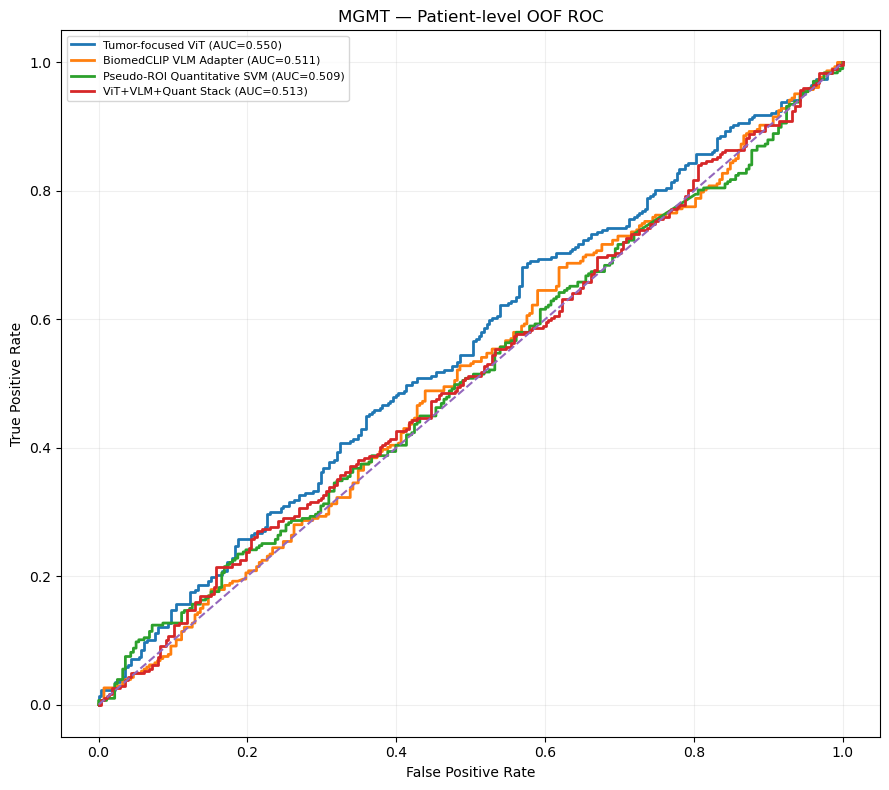

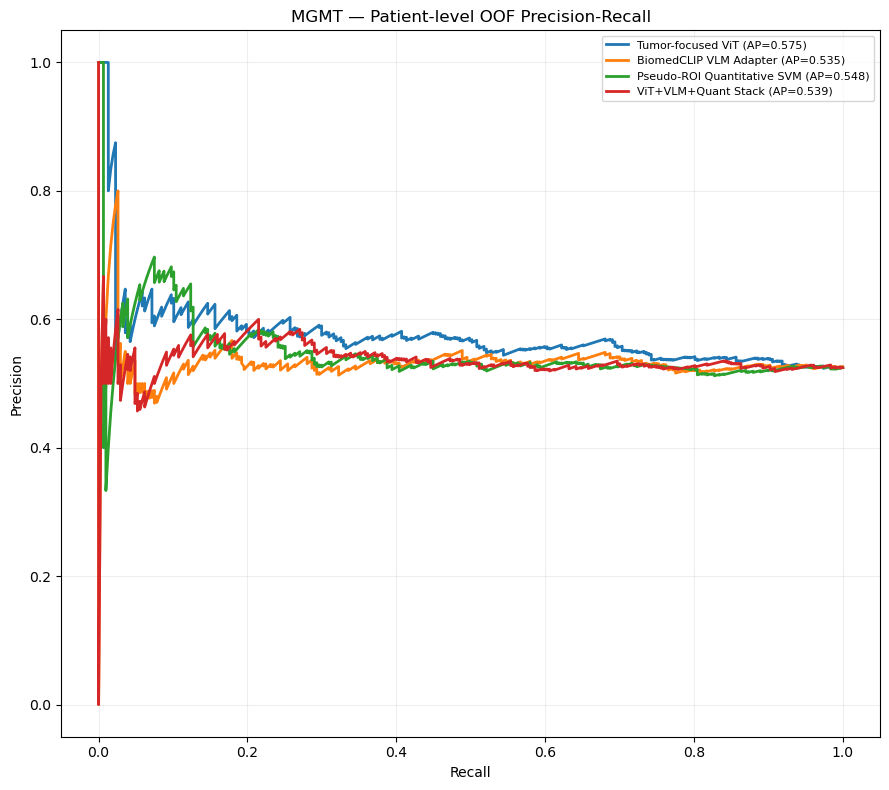

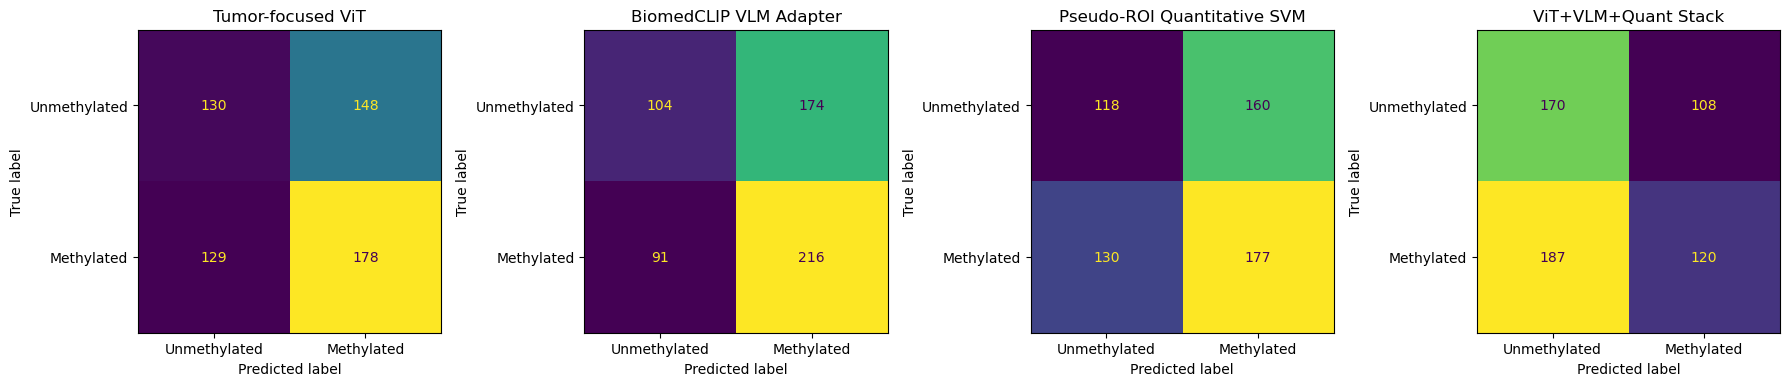

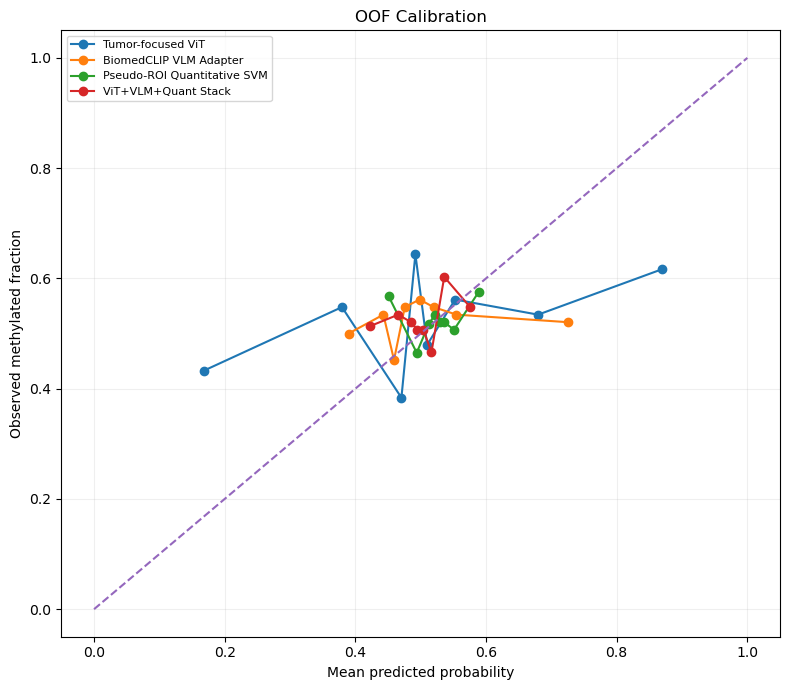

In [25]:
plt.figure(figsize=(9, 8))
for name, (prob, _) in OOF_MODELS.items():
    fpr, tpr, _ = roc_curve(y_all, prob)
    auc = roc_auc_score(y_all, prob)
    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC={auc:.3f})"
    )
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("MGMT — Patient-level OOF ROC")
plt.legend(fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "oof_roc.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

plt.figure(figsize=(9, 8))
for name, (prob, _) in OOF_MODELS.items():
    precision, recall, _ = precision_recall_curve(
        y_all,
        prob
    )
    ap = average_precision_score(y_all, prob)
    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{name} (AP={ap:.3f})"
    )
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("MGMT — Patient-level OOF Precision-Recall")
plt.legend(fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "oof_pr.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

fig, axes = plt.subplots(
    1,
    len(OOF_MODELS),
    figsize=(18, 4.5)
)

for ax, (name, (prob, pred_tuned)) in zip(
    axes,
    OOF_MODELS.items()
):
    cm = confusion_matrix(
        y_all,
        pred_tuned,
        labels=[0, 1]
    )

    ConfusionMatrixDisplay(
        cm,
        display_labels=["Unmethylated", "Methylated"]
    ).plot(
        ax=ax,
        colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "nested_threshold_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

plt.figure(figsize=(8, 7))
for name, (prob, _) in OOF_MODELS.items():
    pt, pp = calibration_curve(
        y_all,
        prob,
        n_bins=8,
        strategy="quantile"
    )
    plt.plot(
        pp,
        pt,
        marker="o",
        label=name
    )
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed methylated fraction")
plt.title("OOF Calibration")
plt.legend(fontsize=8)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "oof_calibration.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 26. Save patient-level OOF predictions

In [26]:
oof_df = labels[
    ["BraTS21ID", "MGMT_value", "outer_fold"]
].copy()

oof_df["vit_probability"] = vit_oof
oof_df["vit_nested_prediction"] = vit_oof_pred_tuned
oof_df["vlm_probability"] = vlm_oof
oof_df["vlm_nested_prediction"] = vlm_oof_pred_tuned
oof_df["quant_probability"] = quant_oof
oof_df["quant_nested_prediction"] = quant_oof_pred_tuned
oof_df["stack_probability"] = stack_oof
oof_df["stack_nested_prediction"] = stack_oof_pred_tuned

oof_df.to_csv(
    OUTPUT_DIR / "all_patient_oof_predictions.csv",
    index=False
)

display(oof_df.head())

,BraTS21ID,MGMT_value,outer_fold,vit_probability,vit_nested_prediction,vlm_probability,vlm_nested_prediction,quant_probability,quant_nested_prediction,stack_probability,stack_nested_prediction
0,00000,1,2,0.516279,1,0.413743,0,0.532392,0,0.502895,0
1,00002,1,0,0.608448,1,0.528367,1,0.561679,1,0.501045,0
2,00003,0,1,0.523980,1,0.445597,1,0.492874,0,0.506331,0
3,00005,1,2,0.496120,0,0.839652,1,0.527957,0,0.529723,1
4,00006,1,1,0.527343,1,0.479632,1,0.590704,1,0.472067,0


## 27. Explainability — exclude organizer-flagged cases from representative images

In [27]:
# Grad-CAM/Grad-CAM++ explain the ViT branch, so TP/TN/FP/FN cases for
# spatial XAI must be selected using the ViT prediction itself.
# The overall best-model cases are still saved separately below.

# Overall best-model cases for general error analysis.
BEST_MODEL_NAME = comparison.iloc[0]["model"]
BEST_PROB, BEST_PRED = OOF_MODELS[BEST_MODEL_NAME]

overall_case_df = oof_df.copy()
overall_case_df["best_model"] = BEST_MODEL_NAME
overall_case_df["best_probability"] = BEST_PROB
overall_case_df["best_prediction"] = BEST_PRED
overall_case_df["category"] = np.select(
    [
        (overall_case_df["MGMT_value"] == 1) & (overall_case_df["best_prediction"] == 1),
        (overall_case_df["MGMT_value"] == 0) & (overall_case_df["best_prediction"] == 0),
        (overall_case_df["MGMT_value"] == 0) & (overall_case_df["best_prediction"] == 1),
        (overall_case_df["MGMT_value"] == 1) & (overall_case_df["best_prediction"] == 0),
    ],
    ["TP", "TN", "FP", "FN"],
    default="other"
)
overall_case_df.to_csv(
    EXPLAIN_DIR / "overall_best_model_error_analysis.csv",
    index=False
)

# ViT-specific cases for spatial explainability.
case_df = oof_df.copy()
case_df["vit_probability_for_xai"] = vit_oof
case_df["vit_prediction_for_xai"] = vit_oof_pred_tuned
case_df["category"] = np.select(
    [
        (case_df["MGMT_value"] == 1) & (case_df["vit_prediction_for_xai"] == 1),
        (case_df["MGMT_value"] == 0) & (case_df["vit_prediction_for_xai"] == 0),
        (case_df["MGMT_value"] == 0) & (case_df["vit_prediction_for_xai"] == 1),
        (case_df["MGMT_value"] == 1) & (case_df["vit_prediction_for_xai"] == 0),
    ],
    ["TP", "TN", "FP", "FN"],
    default="other"
)

# Keep flagged IDs in the primary model, but do not use them as representative XAI cases.
xai_candidates = case_df[
    ~case_df["BraTS21ID"].isin(FLAGGED_IDS)
].copy()

representatives = {}

for cat in ["TP", "TN", "FP", "FN"]:
    d = xai_candidates[
        xai_candidates["category"] == cat
    ].copy()

    if len(d) == 0:
        continue

    if cat in ["TP", "FP"]:
        representatives[cat] = d.sort_values(
            "vit_probability_for_xai",
            ascending=False
        ).iloc[0]
    else:
        representatives[cat] = d.sort_values(
            "vit_probability_for_xai",
            ascending=True
        ).iloc[0]

rep_df = pd.DataFrame(representatives).T
display(rep_df[
    [
        "BraTS21ID",
        "MGMT_value",
        "vit_probability_for_xai",
        "vit_prediction_for_xai",
        "outer_fold"
    ]
])
rep_df.to_csv(
    EXPLAIN_DIR / "vit_representative_cases.csv"
)

,BraTS21ID,MGMT_value,vit_probability_for_xai,vit_prediction_for_xai,outer_fold
TP,00704,1,0.974674,1,3
TN,00349,0,0.012178,0,3
FP,00796,0,0.954016,1,3
FN,00139,1,0.012897,0,3


## 28. ViT Grad-CAM / Grad-CAM++ on tumor-focused views

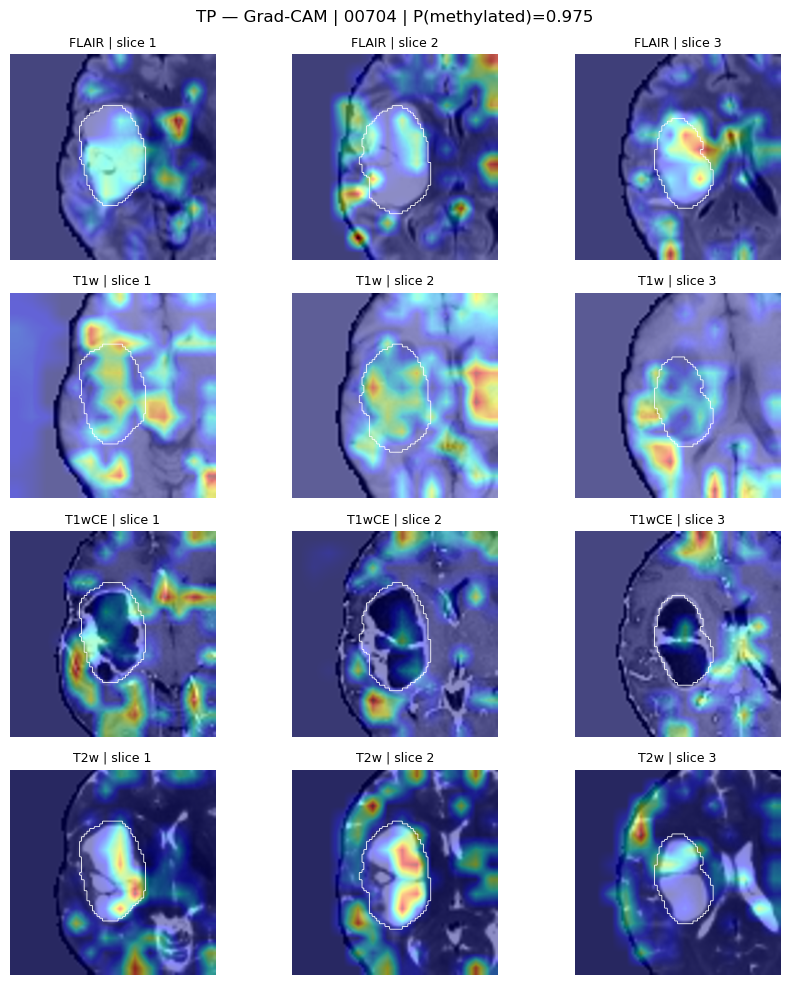

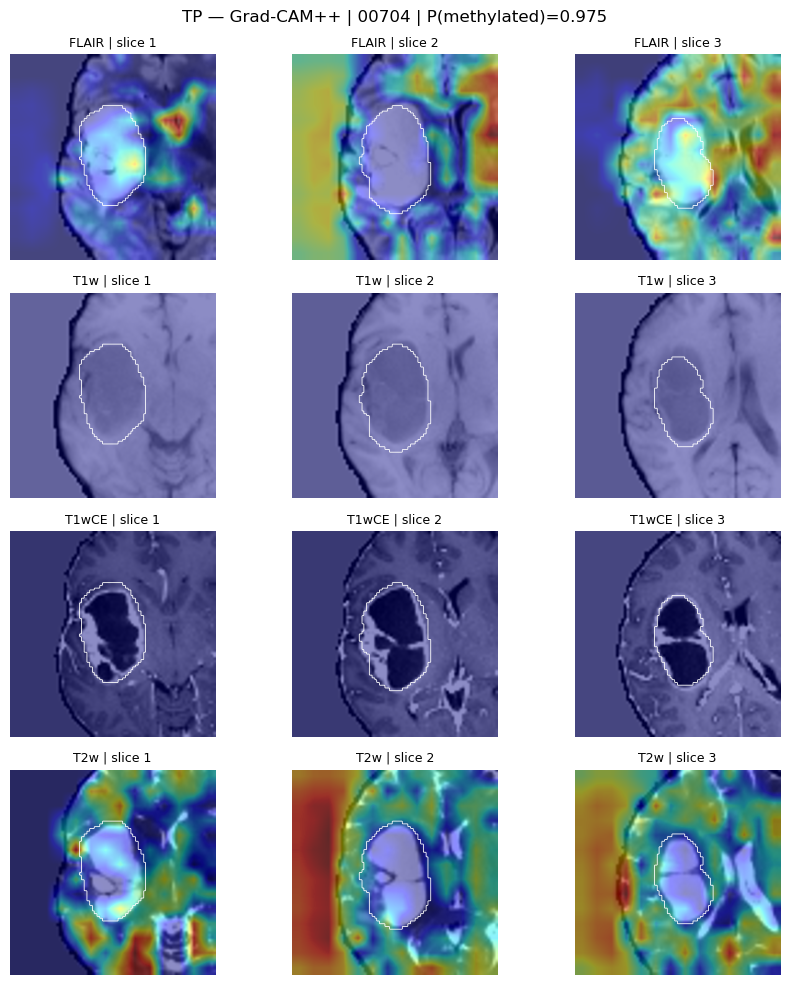

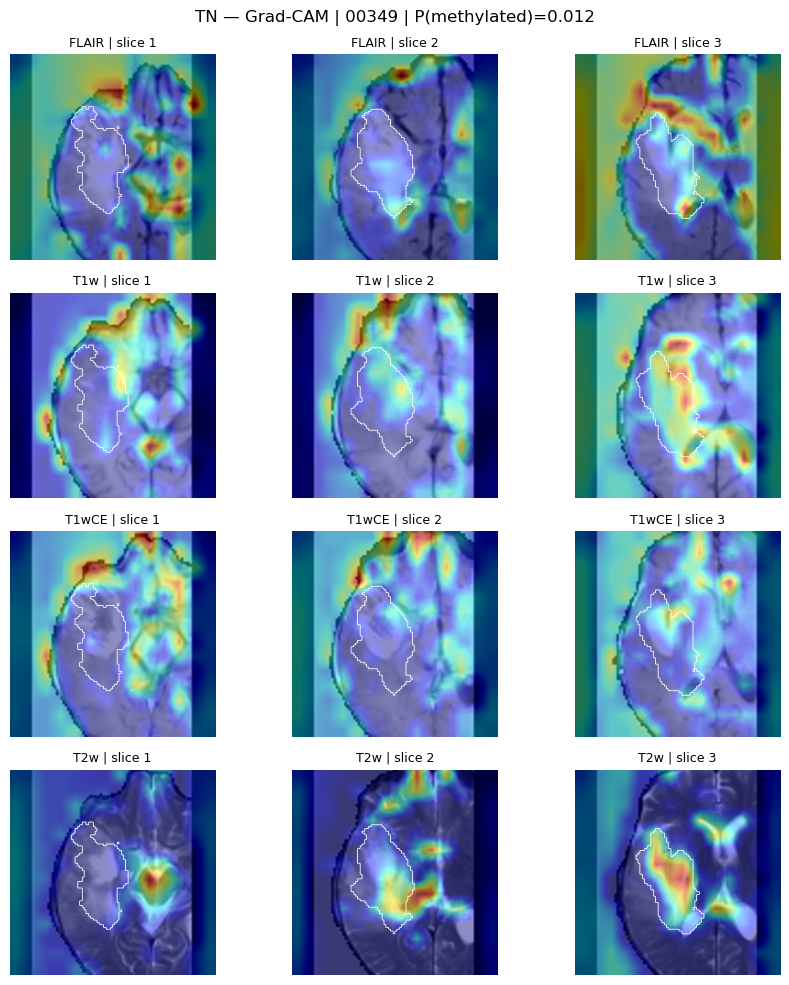

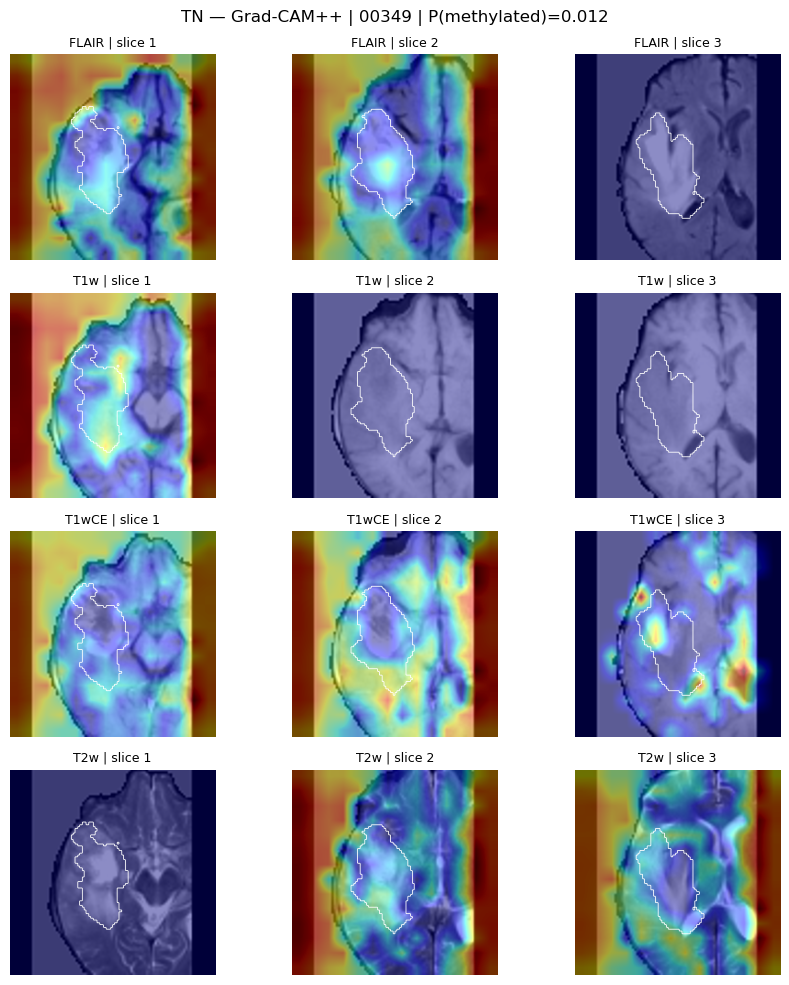

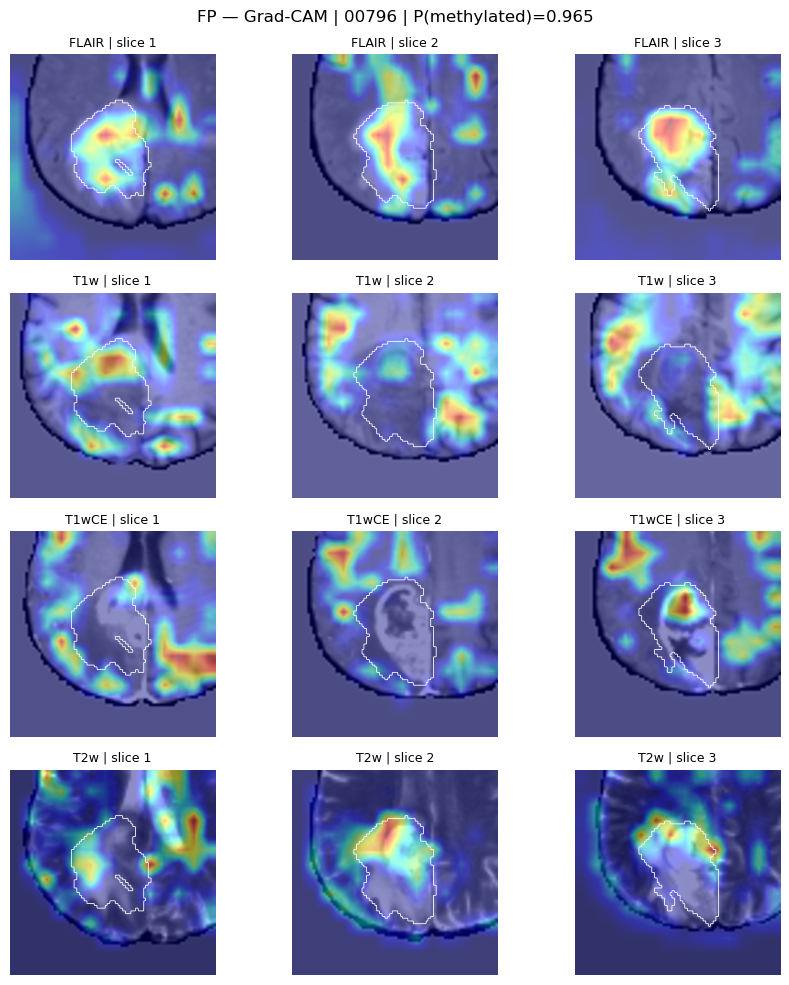

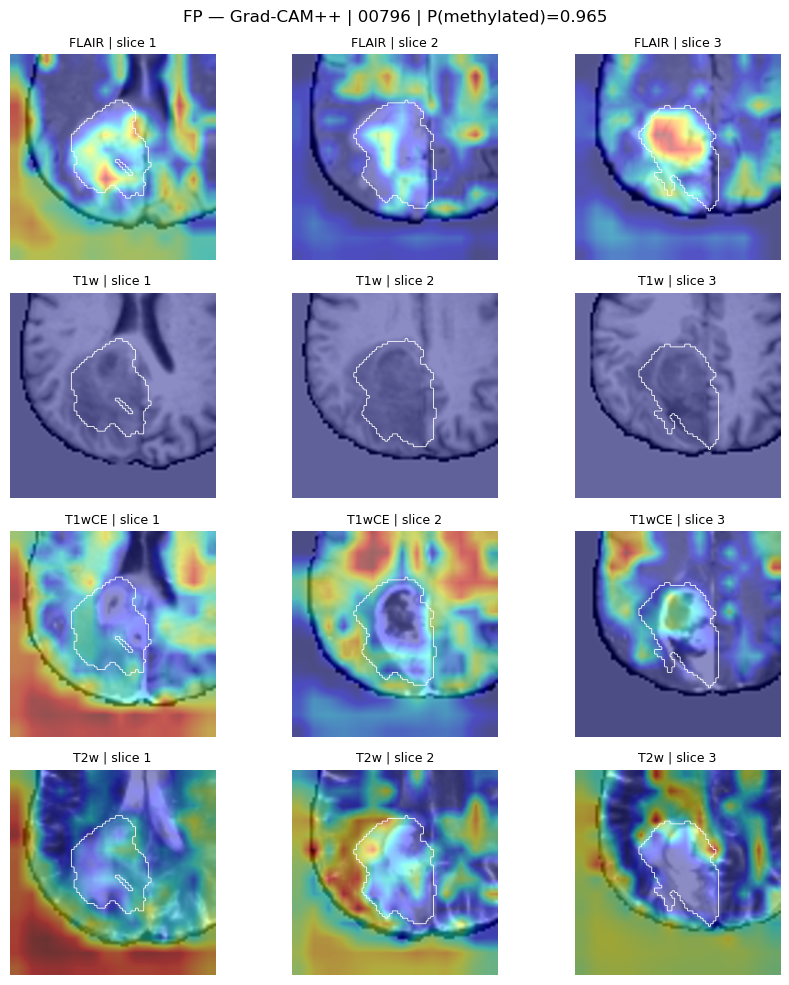

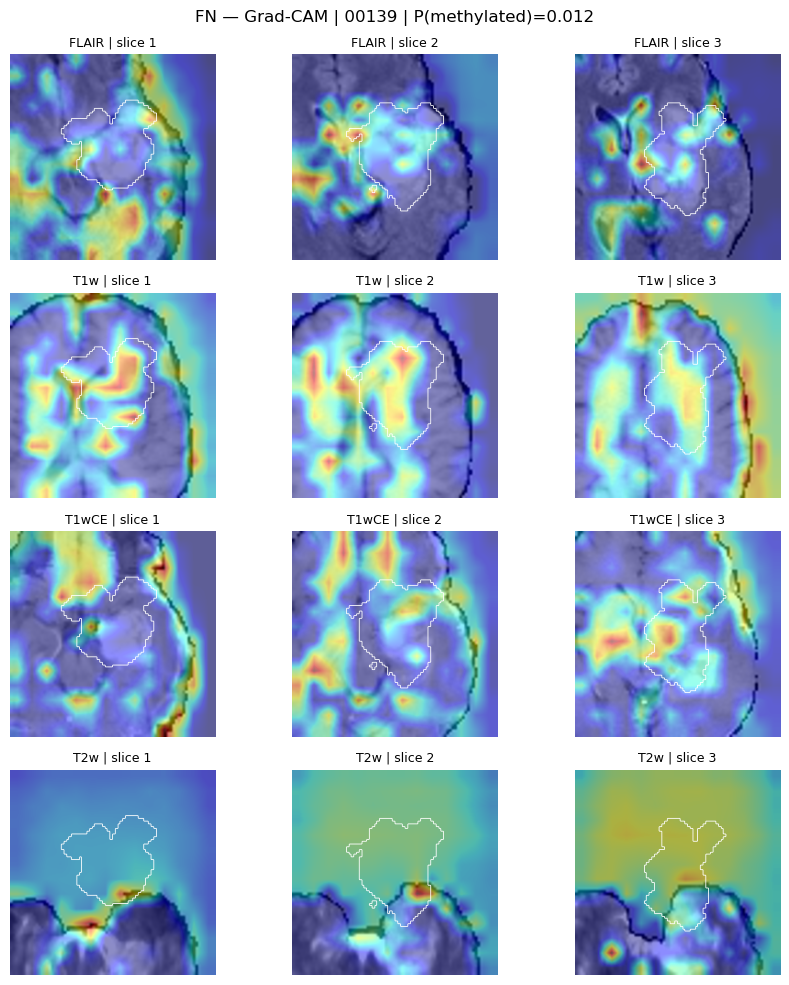

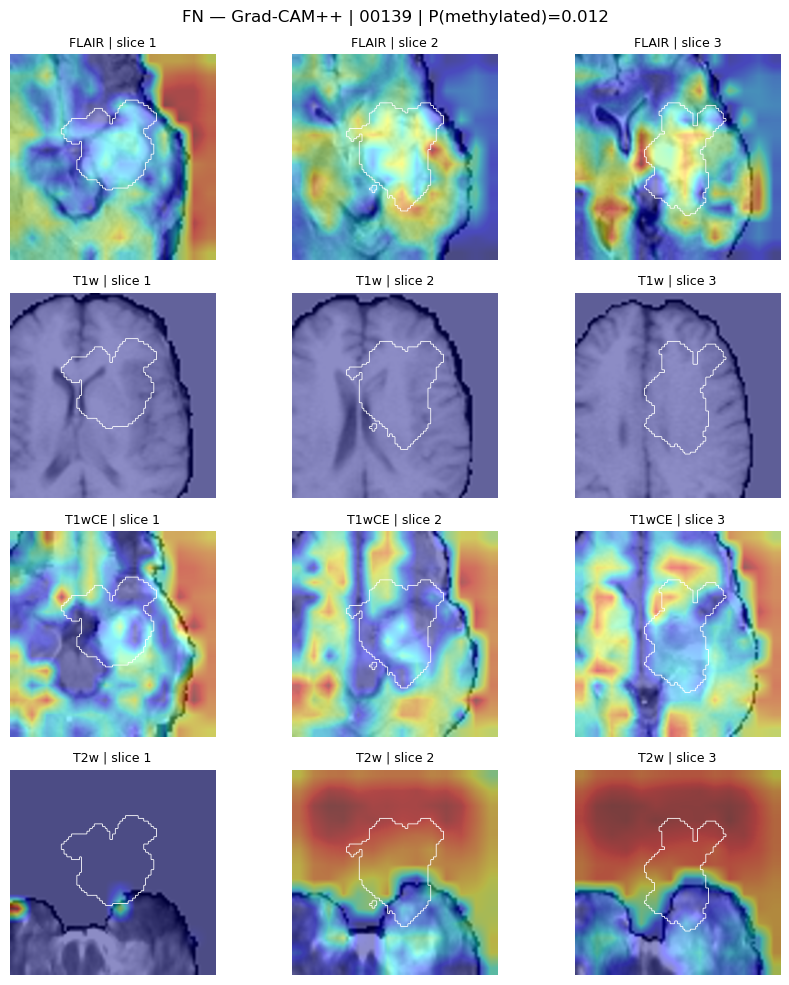

In [28]:
def normalize_map(x):
    x = np.asarray(x, dtype=np.float32)
    x -= np.nanmin(x)
    mx = np.nanmax(x)
    if mx > 1e-8:
        x /= mx
    return np.clip(x, 0, 1)


def overlay_heatmap(gray, heat, alpha=0.45):
    gray = np.asarray(gray, dtype=np.float32) / 255.0
    heat = normalize_map(heat)
    heat_rgb = plt.get_cmap("jet")(heat)[..., :3]
    gray_rgb = np.repeat(
        gray[..., None],
        3,
        axis=2
    )
    return np.clip(
        (1 - alpha) * gray_rgb
        + alpha * heat_rgb,
        0,
        1
    )


class Hook:
    def __init__(self, module):
        self.activation = None
        self.gradient = None
        self.handle = module.register_forward_hook(
            self.forward
        )

    def forward(self, module, inp, out):
        self.activation = out
        if out.requires_grad:
            out.register_hook(self.backward)

    def backward(self, grad):
        self.gradient = grad

    def close(self):
        self.handle.remove()


def patch_grid(model):
    gs = getattr(
        model.backbone.patch_embed,
        "grid_size",
        None
    )
    if gs is not None:
        return int(gs[0]), int(gs[1])

    n = int(model.backbone.patch_embed.num_patches)
    side = int(round(math.sqrt(n)))
    return side, side


def patient_tensor(pid):
    cache = load_patient_cache(pid)
    x = tiles_to_tensor(
        cache["tiles"]
    ).unsqueeze(0).to(DEVICE)
    return cache, x


def patient_fold(pid):
    return int(
        labels.loc[
            labels["BraTS21ID"] == str(pid).zfill(5),
            "outer_fold"
        ].iloc[0]
    )


def multiview_cam(pid, method="gradcam", target_class=None):
    pid = str(pid).zfill(5)
    fold = patient_fold(pid)
    model = load_vit_model(
        MODEL_DIR / f"vit_fold_{fold}.pt"
    )
    cache, x = patient_tensor(pid)

    target_layer = model.backbone.blocks[-1].norm1
    hook = Hook(target_layer)

    model.zero_grad(set_to_none=True)
    logits = model(x)
    prob = torch.sigmoid(logits)[0]

    if target_class is None:
        target_class = int(
            prob.detach().cpu() >= 0.5
        )

    objective = (
        logits[0]
        if target_class == 1
        else -logits[0]
    )
    objective.backward()

    A = hook.activation.detach()
    G = hook.gradient.detach()
    hook.close()

    prefix = int(
        getattr(
            model.backbone,
            "num_prefix_tokens",
            1
        )
    )

    A = A[:, prefix:, :]
    G = G[:, prefix:, :]

    gh, gw = patch_grid(model)
    n = gh * gw

    A = A[:, :n, :].reshape(
        N_VIEWS, gh, gw, -1
    )
    G = G[:, :n, :].reshape(
        N_VIEWS, gh, gw, -1
    )

    if method == "gradcam":
        w = G.mean(
            dim=(1, 2),
            keepdim=True
        )
        cam = torch.relu(
            (w * A).sum(dim=-1)
        )
    elif method in ["gradcam++", "gradcampp"]:
        g2 = G.pow(2)
        g3 = g2 * G

        denom = (
            2 * g2
            + (A * g3).sum(
                dim=(1, 2),
                keepdim=True
            )
        )
        denom = torch.where(
            denom.abs() > 1e-8,
            denom,
            torch.ones_like(denom)
        )

        alpha = g2 / (denom + 1e-8)
        w = (
            alpha * torch.relu(G)
        ).sum(
            dim=(1, 2),
            keepdim=True
        )
        cam = torch.relu(
            (w * A).sum(dim=-1)
        )
    else:
        raise ValueError(method)

    cam = F.interpolate(
        cam.unsqueeze(1),
        size=(IMAGE_SIZE, IMAGE_SIZE),
        mode="bilinear",
        align_corners=False
    ).squeeze(1)

    cams = np.stack([
        normalize_map(
            cam[i].cpu().numpy()
        )
        for i in range(N_VIEWS)
    ])

    out = {
        "patient_id": pid,
        "probability": float(prob.detach().cpu()),
        "tiles": cache["tiles"],
        "mask_tiles": cache["mask_tiles"],
        "cams": cams,
    }

    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return out


def plot_cam_result(result, title, filename):
    fig, axes = plt.subplots(
        N_MODALITIES,
        SLICES_PER_MODALITY,
        figsize=(9, 10)
    )

    for m in range(N_MODALITIES):
        for s in range(SLICES_PER_MODALITY):
            idx = m * SLICES_PER_MODALITY + s
            ax = axes[m, s]

            ax.imshow(
                overlay_heatmap(
                    result["tiles"][idx],
                    result["cams"][idx]
                )
            )

            # Pseudo ROI contour.
            mask = result["mask_tiles"][s]
            ax.contour(
                mask,
                levels=[0.5],
                colors="white",
                linewidths=0.6
            )

            ax.axis("off")
            ax.set_title(
                f"{MODALITIES[m]} | slice {s+1}",
                fontsize=9
            )

    fig.suptitle(
        f"{title} | {result['patient_id']} | "
        f"P(methylated)={result['probability']:.3f}"
    )
    plt.tight_layout()
    plt.savefig(
        EXPLAIN_DIR / filename,
        dpi=250,
        bbox_inches="tight"
    )
    plt.show()


for cat, row in representatives.items():
    pid = str(row["BraTS21ID"]).zfill(5)
    target = int(row["vit_prediction_for_xai"])

    gc_result = multiview_cam(
        pid,
        method="gradcam",
        target_class=target
    )
    plot_cam_result(
        gc_result,
        f"{cat} — Grad-CAM",
        f"{cat}_{pid}_gradcam.png"
    )

    gcpp_result = multiview_cam(
        pid,
        method="gradcam++",
        target_class=target
    )
    plot_cam_result(
        gcpp_result,
        f"{cat} — Grad-CAM++",
        f"{cat}_{pid}_gradcampp.png"
    )

## 29. ViT occlusion sensitivity + multi-branch explainability dashboard

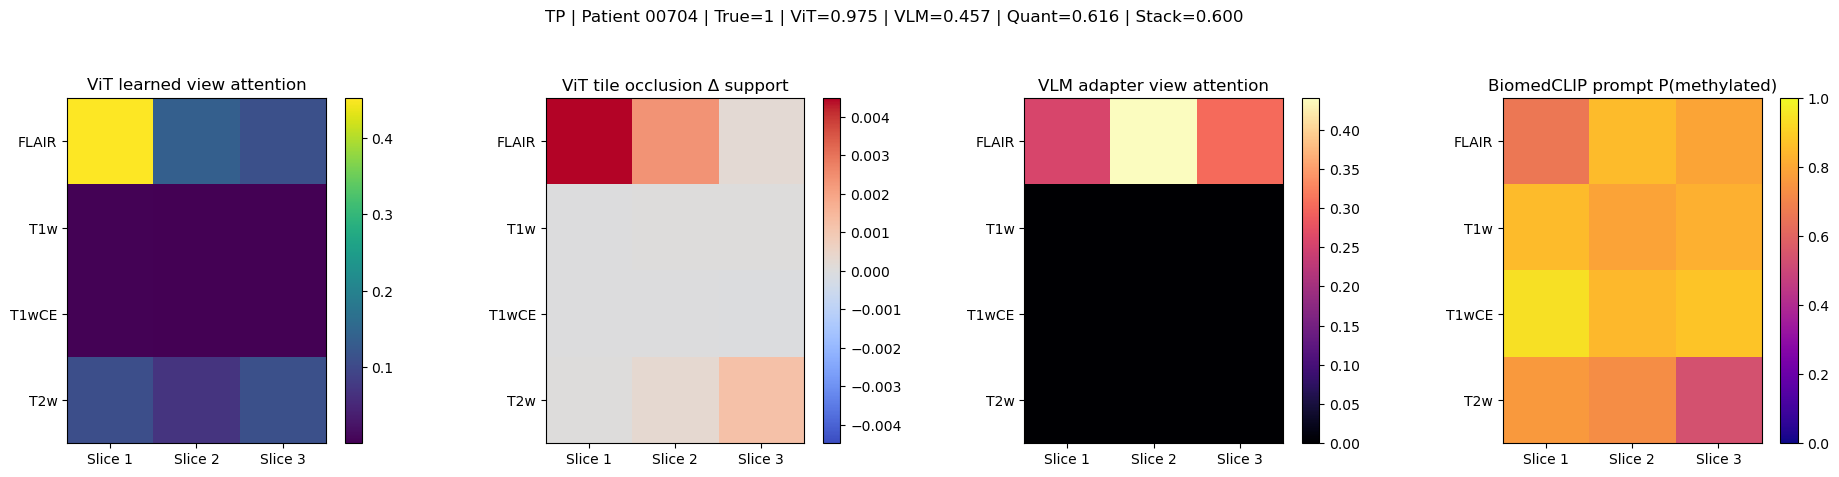

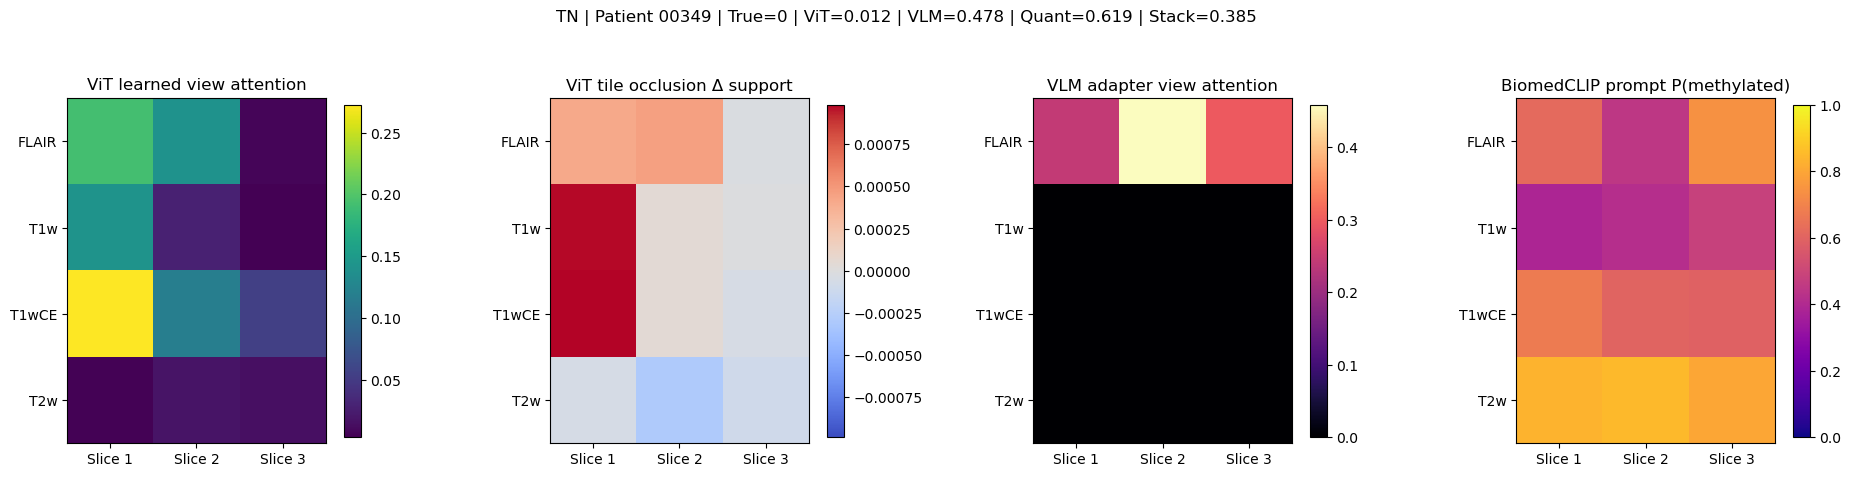

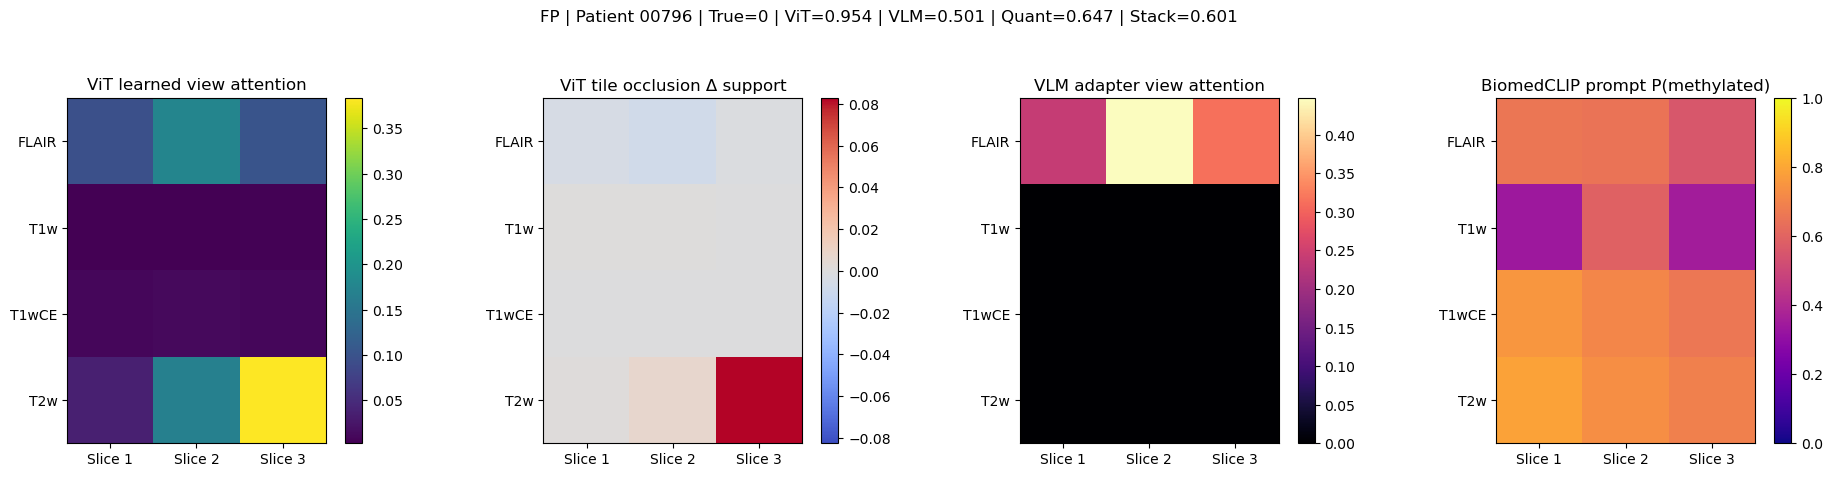

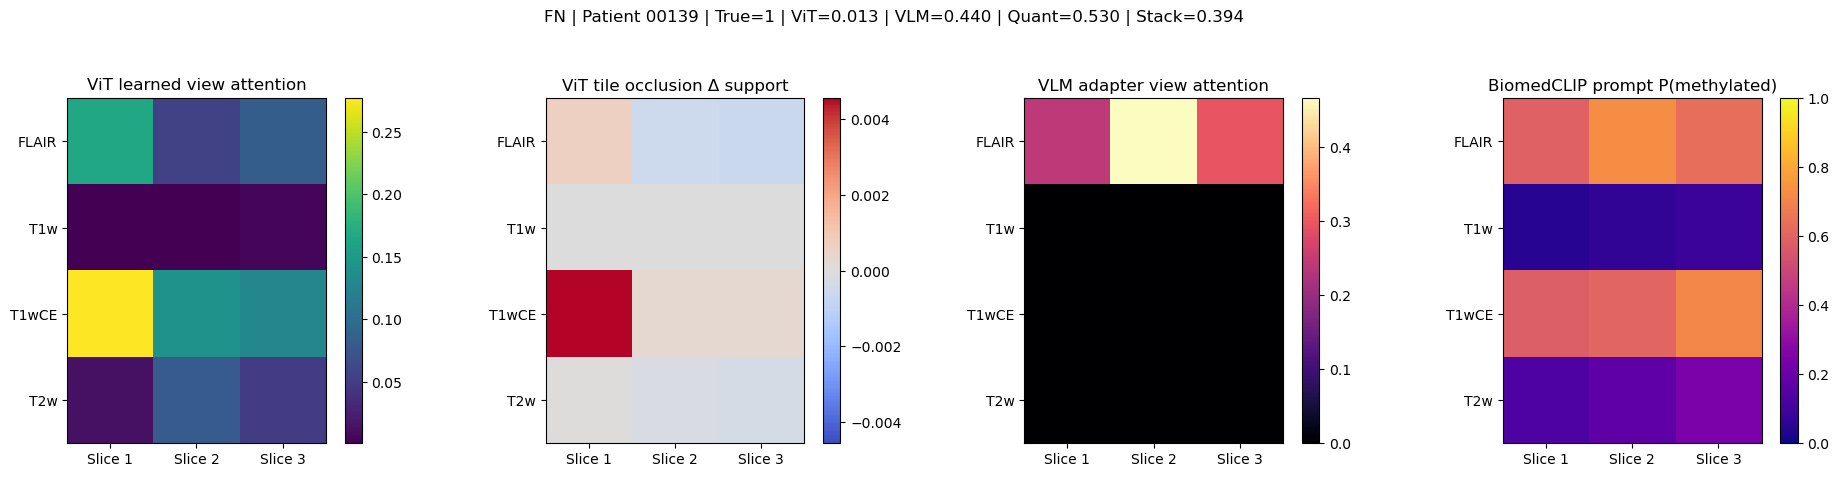

In [29]:
@torch.no_grad()
def vit_tile_occlusion(pid, target_class=None):
    pid = str(pid).zfill(5)
    fold = patient_fold(pid)
    model = load_vit_model(
        MODEL_DIR / f"vit_fold_{fold}.pt"
    )

    cache, x = patient_tensor(pid)

    base_prob = float(
        torch.sigmoid(model(x))[0].cpu()
    )

    if target_class is None:
        row_idx = labels.index[
            labels["BraTS21ID"] == pid
        ].tolist()[0]
        target_class = int(
            vit_oof_pred_tuned[row_idx]
        )

    base_support = (
        base_prob if target_class == 1
        else 1.0 - base_prob
    )

    importance = []

    for view_idx in range(N_VIEWS):
        xo = x.clone()
        # Zero after ImageNet normalization roughly corresponds to mean-image input.
        xo[:, view_idx] = 0.0

        p = float(
            torch.sigmoid(model(xo))[0].cpu()
        )
        support = (
            p if target_class == 1
            else 1.0 - p
        )
        importance.append(
            base_support - support
        )

    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return np.asarray(importance), base_prob


def explainability_dashboard(pid, category):
    pid = str(pid).zfill(5)
    idx = labels.index[
        labels["BraTS21ID"] == pid
    ].tolist()[0]

    vit_attn = vit_attention_oof[idx].reshape(
        N_MODALITIES,
        SLICES_PER_MODALITY
    )
    vlm_attn = vlm_attention_oof[idx].reshape(
        N_MODALITIES,
        SLICES_PER_MODALITY
    )

    occ, base_prob = vit_tile_occlusion(
        pid,
        target_class=int(
            vit_oof_pred_tuned[idx]
        )
    )
    occ = occ.reshape(
        N_MODALITIES,
        SLICES_PER_MODALITY
    )

    prompt = VLM_PROMPT[idx].reshape(
        N_MODALITIES,
        SLICES_PER_MODALITY
    )

    fig, axes = plt.subplots(
        1, 4,
        figsize=(19, 4.5)
    )

    im0 = axes[0].imshow(
        vit_attn,
        cmap="viridis"
    )
    axes[0].set_title("ViT learned view attention")
    plt.colorbar(im0, ax=axes[0], fraction=0.046)

    vmax = max(
        1e-6,
        float(np.max(np.abs(occ)))
    )
    im1 = axes[1].imshow(
        occ,
        cmap="coolwarm",
        vmin=-vmax,
        vmax=vmax
    )
    axes[1].set_title("ViT tile occlusion Δ support")
    plt.colorbar(im1, ax=axes[1], fraction=0.046)

    im2 = axes[2].imshow(
        vlm_attn,
        cmap="magma"
    )
    axes[2].set_title("VLM adapter view attention")
    plt.colorbar(im2, ax=axes[2], fraction=0.046)

    im3 = axes[3].imshow(
        prompt,
        cmap="plasma",
        vmin=0,
        vmax=1
    )
    axes[3].set_title("BiomedCLIP prompt P(methylated)")
    plt.colorbar(im3, ax=axes[3], fraction=0.046)

    for ax in axes:
        ax.set_xticks(
            range(SLICES_PER_MODALITY)
        )
        ax.set_xticklabels(
            ["Slice 1", "Slice 2", "Slice 3"]
        )
        ax.set_yticks(
            range(N_MODALITIES)
        )
        ax.set_yticklabels(
            MODALITIES
        )

    row = oof_df.iloc[idx]
    fig.suptitle(
        f"{category} | Patient {pid} | True={int(row['MGMT_value'])} | "
        f"ViT={row['vit_probability']:.3f} | "
        f"VLM={row['vlm_probability']:.3f} | "
        f"Quant={row['quant_probability']:.3f} | "
        f"Stack={row['stack_probability']:.3f}",
        y=1.05
    )

    plt.tight_layout()
    plt.savefig(
        EXPLAIN_DIR / f"{category}_{pid}_xai_dashboard.png",
        dpi=250,
        bbox_inches="tight"
    )
    plt.show()


for cat, row in representatives.items():
    explainability_dashboard(
        row["BraTS21ID"],
        cat
    )

## 29. Global modality importance from ViT and VLM attention

In [30]:
attention_rows = []

for i, row in labels.iterrows():
    pid = str(row["BraTS21ID"])

    for source_name, attn_arr in [
        ("ViT", vit_attention_oof),
        ("VLM", vlm_attention_oof),
    ]:
        attn = attn_arr[i]

        for m in range(N_MODALITIES):
            start = m * SLICES_PER_MODALITY
            end = start + SLICES_PER_MODALITY

            attention_rows.append({
                "BraTS21ID": pid,
                "MGMT_value": int(row["MGMT_value"]),
                "source": source_name,
                "modality": MODALITIES[m],
                "attention": float(
                    np.nansum(attn[start:end])
                )
            })

attention_df = pd.DataFrame(attention_rows)
attention_df.to_csv(
    EXPLAIN_DIR / "global_modality_attention.csv",
    index=False
)

summary_attention = (
    attention_df
    .groupby(
        ["source", "MGMT_value", "modality"]
    )["attention"]
    .mean()
    .reset_index()
)

display(summary_attention)

,source,MGMT_value,modality,attention
0,VLM,0,FLAIR,0.290673
1,VLM,0,T1w,0.000000
2,VLM,0,T1wCE,0.511485
3,VLM,0,T2w,0.197842
4,VLM,1,FLAIR,0.287785
5,VLM,1,T1w,0.000000
6,VLM,1,T1wCE,0.510261
7,VLM,1,T2w,0.201954
8,ViT,0,FLAIR,0.421531
9,ViT,0,T1w,0.203386


## 30. Global Grad-CAM summary on up to 100 OOF patients

In [31]:
rng = np.random.default_rng(SEED)

eligible_idx = np.where(
    ~labels["BraTS21ID"].isin(FLAGGED_IDS).values
)[0]

sample_idx = rng.choice(
    eligible_idx,
    size=min(N_GLOBAL_GRADCAM, len(eligible_idx)),
    replace=False
)

global_cam_rows = []

for idx in tqdm(
    sample_idx,
    desc="Global Grad-CAM"
):
    pid = str(labels.iloc[idx]["BraTS21ID"])
    pred = int(vit_oof_pred_tuned[idx])

    try:
        result = multiview_cam(
            pid,
            method="gradcam",
            target_class=pred
        )

        for m in range(N_MODALITIES):
            start = m * SLICES_PER_MODALITY
            end = start + SLICES_PER_MODALITY

            score = float(
                result["cams"][start:end].mean()
            )

            global_cam_rows.append({
                "BraTS21ID": pid,
                "MGMT_value": int(y_all[idx]),
                "prediction": pred,
                "correct": int(pred == y_all[idx]),
                "modality": MODALITIES[m],
                "mean_gradcam": score
            })
    except Exception as e:
        print("CAM failed:", pid, repr(e))

global_cam_df = pd.DataFrame(global_cam_rows)
global_cam_df.to_csv(
    EXPLAIN_DIR / "global_gradcam_100patients.csv",
    index=False
)

if len(global_cam_df):
    display(
        global_cam_df
        .groupby(
            ["correct", "modality"]
        )["mean_gradcam"]
        .mean()
        .reset_index()
    )

Global Grad-CAM:   0%|          | 0/100 [00:00<?, ?it/s]

,correct,modality,mean_gradcam
0,0,FLAIR,0.164643
1,0,T1w,0.176267
2,0,T1wCE,0.168635
3,0,T2w,0.165502
4,1,FLAIR,0.161940
5,1,T1w,0.162949
6,1,T1wCE,0.167358
7,1,T2w,0.155869


# 31. Train FINAL ViT on 100% of usable labeled patients

This model is **not** used to estimate performance.  
The OOF results above remain the thesis performance numbers.

The final model uses every usable labeled patient.

In [32]:
FINAL_VIT = None

if TRAIN_FINAL_ALL_DATA_MODELS:
    # ================================================================
    # HARD CLEANUP BEFORE THE FINAL ALL-DATA ViT
    # ================================================================
    # At this point OOF ViT, BiomedCLIP, VLM adapters and XAI may all have
    # existed in the same kernel. Remove stale CUDA references first.
    aggressive_cuda_cleanup(
        move_biomedclip_to_cpu=True,
        purge_all_cuda_globals=True,
        verbose=True
    )

    ensure_gpu_memory(
        min_free_gib=6.0,
        stage="final all-patient ViT training"
    )

    final_vit_epochs = int(
        max(
            1,
            round(
                np.median(
                    [x for x in vit_best_epochs if x > 0]
                    or [VIT_FINETUNE_EPOCHS]
                )
            )
        )
    )

    print(
        "Final ViT fine-tune epochs:",
        final_vit_epochs
    )
    print(
        "Final ViT batch size:",
        FINAL_VIT_BATCH_SIZE
    )

    full_loader = make_image_loader(
        labels,
        True,
        FINAL_VIT_BATCH_SIZE
    )

    final_model = TumorFocusedMultiViewViT().to(DEVICE)

    n_pos = int(y_all.sum())
    n_neg = int(len(y_all) - n_pos)

    final_pos_weight = torch.tensor(
        [n_neg / max(1, n_pos)],
        dtype=torch.float32,
        device=DEVICE
    )

    # ---------------- warmup ----------------
    freeze_vit_backbone(final_model)

    final_opt = make_vit_optimizer(
        final_model,
        backbone_lr=0.0,
        head_lr=VIT_HEAD_LR
    )

    for warmup_epoch in range(VIT_HEAD_EPOCHS):
        loss = train_image_epoch(
            final_model,
            full_loader,
            final_opt,
            final_pos_weight
        )
        print(
            f"final ViT warmup {warmup_epoch+1}/{VIT_HEAD_EPOCHS}: "
            f"loss={loss:.4f}"
        )

    # The warmup optimizer can hold GPU state; remove it before fine-tuning.
    del final_opt
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    # ---------------- partial fine-tune ----------------
    unfreeze_vit_tail(final_model)

    final_opt = make_vit_optimizer(
        final_model,
        backbone_lr=VIT_BACKBONE_LR,
        head_lr=VIT_FINETUNE_HEAD_LR
    )

    final_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        final_opt,
        T_max=max(1, final_vit_epochs)
    )

    for epoch in range(1, final_vit_epochs + 1):
        loss = train_image_epoch(
            final_model,
            full_loader,
            final_opt,
            final_pos_weight
        )
        final_scheduler.step()

        print(
            f"final ViT {epoch}/{final_vit_epochs}: "
            f"loss={loss:.4f}"
        )

    final_vit_path = (
        MODEL_DIR / "FINAL_vit_all_usable_patients.pt"
    )

    save_torch_model(
        final_model,
        final_vit_path,
        extra={
            "epochs": final_vit_epochs,
            "batch_size": FINAL_VIT_BATCH_SIZE,
            "gradient_accumulation_steps": VIT_GRAD_ACCUM_STEPS
        }
    )

    print("Saved:", final_vit_path)

    # Keep the final trained model, but on CPU so it cannot block VLM training.
    FINAL_VIT = final_model.to("cpu")

    # Delete all remaining GPU-owning training objects explicitly.
    del final_model
    del final_opt
    del final_scheduler
    del final_pos_weight
    del full_loader

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        try:
            torch.cuda.ipc_collect()
        except Exception:
            pass

        free_b, total_b = torch.cuda.mem_get_info()
        print(
            f"CUDA after final ViT cleanup: "
            f"{free_b/1024**3:.2f} GiB free / "
            f"{total_b/1024**3:.2f} GiB total"
        )

CUDA memory after cleanup: 11.19 GiB free / 31.84 GiB total
CUDA memory after cleanup: 11.19 GiB free / 31.84 GiB total
Final ViT fine-tune epochs: 3
Final ViT batch size: 1


  0%|          | 0/585 [00:00<?, ?it/s]

final ViT warmup 1/1: loss=0.6994


  0%|          | 0/585 [00:00<?, ?it/s]

final ViT 1/3: loss=0.6698


  0%|          | 0/585 [00:00<?, ?it/s]

final ViT 2/3: loss=0.6651


  0%|          | 0/585 [00:00<?, ?it/s]

final ViT 3/3: loss=0.6413
Saved: kaggle\working\mgmt_tumorfocused_v3_outputs\models\FINAL_vit_all_usable_patients.pt
CUDA after final ViT cleanup: 11.19 GiB free / 31.84 GiB total


## 32. Train FINAL VLM adapter on 100% of usable labeled patients

In [33]:
FINAL_VLM_ADAPTER = None
FINAL_VLM_SUBSET_NAME = Counter(
    vlm_selected_subsets.values()
).most_common(1)[0][0]

FINAL_VLM_MODALITIES = MODALITY_SUBSETS[
    FINAL_VLM_SUBSET_NAME
]

print(
    "Final VLM subset selected from CV frequency:",
    FINAL_VLM_SUBSET_NAME,
    FINAL_VLM_MODALITIES
)

aggressive_cuda_cleanup(move_biomedclip_to_cpu=True)

if TRAIN_FINAL_ALL_DATA_MODELS:
    final_vlm_epochs = int(
        max(
            1,
            round(
                np.median(
                    [x for x in vlm_best_epochs if x > 0]
                    or [VLM_ADAPTER_EPOCHS]
                )
            )
        )
    )

    model = VLMAdapter(
        embed_dim=VLM_E.shape[-1],
        allowed_modalities=FINAL_VLM_MODALITIES
    ).to(DEVICE)

    full_loader = make_vlm_loader(
        np.arange(len(labels)),
        VLM_E,
        VLM_PROMPT,
        y_all,
        True
    )

    n_pos = int(y_all.sum())
    n_neg = len(y_all) - n_pos

    pos_weight = torch.tensor(
        [n_neg / max(1, n_pos)],
        dtype=torch.float32,
        device=DEVICE
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=VLM_ADAPTER_LR,
        weight_decay=1e-4
    )

    for epoch in range(
        1,
        final_vlm_epochs + 1
    ):
        loss = train_vlm_epoch(
            model,
            full_loader,
            optimizer,
            pos_weight
        )
        print(
            f"final VLM {epoch}/{final_vlm_epochs}: "
            f"loss={loss:.4f}"
        )

    torch.save({
        "state_dict": model.state_dict(),
        "subset_name": FINAL_VLM_SUBSET_NAME,
        "selected_modalities": FINAL_VLM_MODALITIES,
        "embed_dim": int(VLM_E.shape[-1]),
        "epochs": final_vlm_epochs
    }, MODEL_DIR / "FINAL_vlm_adapter_all_usable_patients.pt")

    FINAL_VLM_ADAPTER = model.to("cpu")

    del model, optimizer, pos_weight, full_loader
    aggressive_cuda_cleanup(move_biomedclip_to_cpu=True)

Final VLM subset selected from CV frequency: FLAIR+T1CE ['FLAIR', 'T1wCE']
CUDA memory after cleanup: 11.19 GiB free / 31.84 GiB total
final VLM 1/3: loss=0.6745
final VLM 2/3: loss=0.6605
final VLM 3/3: loss=0.6562
CUDA memory after cleanup: 11.19 GiB free / 31.84 GiB total


## 33. Train FINAL quantitative model + final stacker

In [34]:
FINAL_QUANT = None
FINAL_STACKER = None

if TRAIN_FINAL_ALL_DATA_MODELS:
    n_features = X_quant.shape[1]
    k_options = [
        min(20, n_features),
        min(40, n_features),
        "all"
    ]

    final_quant_grid = GridSearchCV(
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("select", SelectKBest(
                mutual_info_classif,
                k="all"
            )),
            ("svc", SVC(
                probability=True,
                class_weight="balanced",
                random_state=SEED
            ))
        ]),
        param_grid={
            "select__k": k_options,
            "svc__C": [0.1, 1.0, 10.0],
            "svc__gamma": ["scale", 0.01, 0.001],
        },
        scoring="roc_auc",
        cv=StratifiedKFold(
            n_splits=5,
            shuffle=True,
            random_state=SEED
        ),
        n_jobs=-1,
        refit=True
    )

    final_quant_grid.fit(
        X_quant,
        y_all
    )

    FINAL_QUANT = final_quant_grid.best_estimator_
    joblib.dump(
        FINAL_QUANT,
        MODEL_DIR / "FINAL_quantitative_svm_all_usable_patients.joblib"
    )

    # Fit final meta stacker on honest base-model OOF probabilities.
    FINAL_STACKER = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(
            class_weight="balanced",
            C=0.5,
            max_iter=2000,
            random_state=SEED
        ))
    ])
    FINAL_STACKER.fit(
        base_oof,
        y_all
    )

    joblib.dump(
        FINAL_STACKER,
        MODEL_DIR / "FINAL_three_branch_stacker.joblib"
    )

    print(
        "Final quantitative params:",
        final_quant_grid.best_params_
    )

Final quantitative params: {'select__k': 40, 'svc__C': 1.0, 'svc__gamma': 0.001}


# 34. OPTIONAL competition test inference

**Recommended submission mode = fold ensemble.**

Why?
The stacker was trained from OOF-style base predictions.  
Averaging the five ViT/VLM/quantitative fold models produces test probabilities whose calibration is closer to the OOF distributions than a single model trained on 100% of the data.

The all-data final models are still trained and saved above as requested.

In [35]:
if RUN_COMPETITION_TEST_INFERENCE:
    # BiomedCLIP was moved to CPU after training feature extraction.
    # Move it back only for optional test embedding extraction.
    try:
        vlm_model = vlm_model.to(DEVICE)
        TEXT_FEATURES = TEXT_FEATURES.to(DEVICE)
    except Exception:
        pass

    if not TEST_DIR.exists() or not SAMPLE_SUB_PATH.exists():
        raise FileNotFoundError(
            "Competition test data/sample submission missing."
        )

    sample = pd.read_csv(
        SAMPLE_SUB_PATH,
        dtype={"BraTS21ID": str}
    )
    sample["BraTS21ID"] = sample["BraTS21ID"].str.zfill(5)

    test_feature_rows = []
    valid_test_ids = []

    for pid in tqdm(
        sample["BraTS21ID"],
        desc="Preprocessing competition test"
    ):
        try:
            preprocess_patient(
                pid,
                TEST_DIR / pid,
                "test"
            )
            cache = load_patient_cache(
                pid,
                "test"
            )

            f = {"BraTS21ID": pid}
            f.update(cache["features"])
            test_feature_rows.append(f)
            valid_test_ids.append(pid)
        except Exception as e:
            print("Test preprocessing failed:", pid, repr(e))

    valid_test_df = pd.DataFrame({
        "BraTS21ID": valid_test_ids
    })

    # ---------- ViT 5-fold ensemble ----------
    test_loader = make_image_loader(
        valid_test_df,
        False,
        VIT_BATCH_SIZE,
        split_name="test",
        with_labels=False
    )

    @torch.no_grad()
    def predict_unlabeled_vit(model, loader):
        model.eval()
        probs = []
        ids = []

        for x, batch_ids in loader:
            x = x.to(DEVICE)
            p = torch.sigmoid(model(x))

            if USE_TTA:
                pf = torch.sigmoid(
                    model(torch.flip(x, dims=[-1]))
                )
                p = 0.5 * (p + pf)

            probs.extend(p.cpu().numpy().tolist())
            ids.extend(list(batch_ids))

        return np.asarray(probs), ids

    vit_fold_probs = []

    for fold in range(N_FOLDS):
        model = load_vit_model(
            MODEL_DIR / f"vit_fold_{fold}.pt"
        )
        p, ids_vit = predict_unlabeled_vit(
            model,
            test_loader
        )
        vit_fold_probs.append(p)

        del model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    test_vit_prob = np.mean(
        np.stack(vit_fold_probs),
        axis=0
    )

    # ---------- BiomedCLIP embeddings ----------
    # BiomedCLIP was moved to CPU before final ViT/VLM training.
    vlm_model = vlm_model.to(DEVICE)
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    TEST_E, TEST_PROMPT, ids_vlm = extract_vlm_embeddings(
        valid_test_df,
        split_name="test",
        with_labels=False
    )

    vlm_fold_probs = []

    for fold in range(N_FOLDS):
        ckpt = torch.load(
            MODEL_DIR / f"vlm_adapter_fold_{fold}.pt",
            map_location=DEVICE
        )

        adapter = VLMAdapter(
            embed_dim=TEST_E.shape[-1],
            allowed_modalities=ckpt["selected_modalities"]
        ).to(DEVICE)
        adapter.load_state_dict(
            ckpt["state_dict"]
        )
        adapter.eval()

        ds = VLMArrayDataset(
            np.arange(len(valid_test_df)),
            TEST_E,
            TEST_PROMPT,
            y=None
        )
        loader = DataLoader(
            ds,
            batch_size=32,
            shuffle=False,
            num_workers=0
        )

        probs = []

        with torch.no_grad():
            for E, P, _ in loader:
                E = E.to(DEVICE)
                P = P.to(DEVICE)
                probs.extend(
                    torch.sigmoid(
                        adapter(E, P)
                    ).cpu().numpy().tolist()
                )

        vlm_fold_probs.append(
            np.asarray(probs)
        )

        del adapter

    test_vlm_prob = np.mean(
        np.stack(vlm_fold_probs),
        axis=0
    )

    # ---------- Quantitative fold ensemble ----------
    test_quant_df = pd.DataFrame(test_feature_rows)
    test_quant_df = (
        valid_test_df
        .merge(
            test_quant_df,
            on="BraTS21ID",
            how="left"
        )
    )
    X_test_quant = test_quant_df[
        feature_cols
    ].replace(
        [np.inf, -np.inf],
        np.nan
    ).values.astype(np.float32)

    quant_fold_probs = []

    for fold in range(N_FOLDS):
        qmodel = joblib.load(
            MODEL_DIR / f"quant_svm_fold_{fold}.joblib"
        )
        quant_fold_probs.append(
            qmodel.predict_proba(
                X_test_quant
            )[:, 1]
        )

    test_quant_prob = np.mean(
        np.stack(quant_fold_probs),
        axis=0
    )

    # ---------- Stacked probability ----------
    stacker = joblib.load(
        MODEL_DIR / "FINAL_three_branch_stacker.joblib"
    )

    test_stack_prob = stacker.predict_proba(
        np.column_stack([
            test_vit_prob,
            test_vlm_prob,
            test_quant_prob
        ])
    )[:, 1]

    pred_map = dict(
        zip(
            valid_test_df["BraTS21ID"],
            test_stack_prob
        )
    )

    submission = sample.copy()
    fallback = float(y_all.mean())
    submission["MGMT_value"] = (
        submission["BraTS21ID"]
        .map(pred_map)
        .fillna(fallback)
    )

    submission.to_csv(
        "./kaggle/working/submission.csv",
        index=False
    )

    print("Saved /kaggle/working/submission.csv")
    display(submission.head())
else:
    print(
        "Competition inference disabled. "
        "Set RUN_COMPETITION_TEST_INFERENCE=True when needed."
    )

Competition inference disabled. Set RUN_COMPETITION_TEST_INFERENCE=True when needed.


## 35. Experiment metadata and export

In [36]:
config = {
    "usable_labeled_patients": int(len(labels)),
    "primary_metric": "ROC-AUC",
    "evaluation": "5-fold patient-level OOF",
    "final_training": "all usable labeled patients",
    "flagged_ids_kept_in_primary_training": sorted(FLAGGED_IDS),
    "flagged_ids_excluded_from_representative_xai": True,
    "target_spacing_mm": list(TARGET_SPACING_MM),
    "n4_enabled": USE_N4,
    "pseudo_tumor_localization": {
        "percentile": PSEUDO_MASK_PERCENTILE,
        "minimum_component_voxels": MIN_COMPONENT_VOXELS,
        "crop_margin": TUMOR_CROP_MARGIN
    },
    "vit_model": VIT_MODEL_NAME,
    "vit_best_epochs": [int(x) for x in vit_best_epochs],
    "vit_fold_thresholds": {
        str(k): float(v)
        for k, v in vit_fold_thresholds.items()
    },
    "vlm_model": BIOMEDCLIP_NAME,
    "vlm_selected_subsets": {
        str(k): v
        for k, v in vlm_selected_subsets.items()
    },
    "final_vlm_subset": FINAL_VLM_SUBSET_NAME,
    "quantitative_feature_count": int(len(feature_cols)),
    "num_workers": NUM_WORKERS,
}

with open(
    OUTPUT_DIR / "experiment_config.json",
    "w"
) as f:
    json.dump(config, f, indent=2)

import shutil

archive = shutil.make_archive(
    "./kaggle/working/RSNA_MGMT_TumorFocused_AllData_FINAL_RESULTS",
    "zip",
    root_dir=OUTPUT_DIR
)

print("Results archive:", archive)
print(json.dumps(config, indent=2))

Results archive: c:\src\pythonapps\Thesis 1\kaggle\working\RSNA_MGMT_TumorFocused_AllData_FINAL_RESULTS.zip
{
  "usable_labeled_patients": 585,
  "primary_metric": "ROC-AUC",
  "evaluation": "5-fold patient-level OOF",
  "final_training": "all usable labeled patients",
  "flagged_ids_kept_in_primary_training": [
    "00109",
    "00123",
    "00709"
  ],
  "flagged_ids_excluded_from_representative_xai": true,
  "target_spacing_mm": [
    1.5,
    1.5,
    1.5
  ],
  "n4_enabled": false,
  "pseudo_tumor_localization": {
    "percentile": 96.5,
    "minimum_component_voxels": 50,
    "crop_margin": 0.35
  },
  "vit_model": "vit_small_patch16_224.dino",
  "vit_best_epochs": [
    3,
    1,
    1,
    6,
    5
  ],
  "vit_fold_thresholds": {
    "0": 0.46925127506256104,
    "1": 0.4849371016025543,
    "2": 0.497494101524353,
    "3": 0.1385258436203003,
    "4": 0.7150000000000001
  },
  "vlm_model": "hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224",
  "vlm_selected_subse

# 36. How to interpret the final results

## What counts as the main result
Use the **5-fold OOF ROC-AUC** from the model-comparison table.

Do not report the training performance of the final all-data model as accuracy.

## Why final models still train on all data
The final deployable ViT/VLM/quantitative models are trained only after the unbiased OOF experiment has finished. This means the final saved models use the full labeled cohort without contaminating the thesis performance estimate.

## If accuracy improves but AUC does not
That can happen because the new nested thresholds optimize the binary operating point without changing ranking performance. Report both:
- ROC-AUC (primary),
- nested-threshold accuracy / balanced accuracy / sensitivity / specificity (secondary).

## Pseudo-ROI limitation
The tumor focus is automated and does not replace neuroradiologist-approved BraTS segmentation. The thesis should call this:
- automated tumor-likeness localization,
- pseudo-ROI,
- tumor-focused crop,

not “ground-truth tumor segmentation”.

## Highest-priority future upgrade
If expert BraTS tumor masks for the same patients become available, replace the pseudo-ROI with WT/TC/ET masks and rerun the exact same modeling framework.